# Exploratory Data Analysis: Self-Reported Heart Disease

**DSAI5101 — Member 2**

**Research question:** Which demographic, health-related, and lifestyle factors are most strongly associated with self-reported heart disease?

**Analysis population:** Observed training split only (`data/processed/observed/training.csv`). Validation and test data are not used.

**Analysis rules:** Preserve observed missing values; exclude `row_id` and `duplicate_group` from predictors; do not use target-source fields as predictors; retain repeated-response groups; describe associations rather than causes.


## 1. Setup and initial dataset inspection

We first import the analysis libraries, load the observed training split, and inspect the dataset dimensions, columns, data types and target field. This confirms what data are available before examining missingness or feature relationships.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Create output folders before any figure/table export cells run.
figures_folder = Path("../results/figures")
tables_folder = Path("../results/tables")
figures_folder.mkdir(parents=True, exist_ok=True)
tables_folder.mkdir(parents=True, exist_ok=True)


In [2]:
df = pd.read_csv("../data/processed/observed/training.csv")

In [3]:
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["heart_disease"].value_counts(dropna=False))

print("\nMissing target values:")
print(df["heart_disease"].isna().sum())

print("\nExcluded columns:")
print([col for col in ["row_id", "duplicate_group",
                       "HadHeartAttack", "HadAngina"]
       if col in df.columns])

Dataset shape: (308080, 41)

Target distribution:
heart_disease
0    280254
1     27826
Name: count, dtype: int64

Missing target values:
0

Excluded columns:
['row_id', 'duplicate_group']


In [4]:
df.shape

(308080, 41)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 308080 entries, 0 to 308079
Data columns (total 41 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   row_id                     308080 non-null  int64  
 1   duplicate_group            308080 non-null  int64  
 2   State                      308080 non-null  str    
 3   Sex                        308080 non-null  str    
 4   GeneralHealth              307335 non-null  str    
 5   PhysicalHealthDays         300802 non-null  float64
 6   MentalHealthDays           302038 non-null  float64
 7   LastCheckupTime            302491 non-null  str    
 8   PhysicalActivities         307397 non-null  str    
 9   SleepHours                 304555 non-null  float64
 10  RemovedTeeth               300481 non-null  str    
 11  HadStroke                  307383 non-null  str    
 12  HadAsthma                  307096 non-null  str    
 13  HadSkinCancer              306210 non-nu

### Initial inspection — interpretation

The observed training dataset contains **308,080 rows and 41 columns**. It includes demographic, health-related and lifestyle information, together with the `heart_disease` target.

The next step is to assess completeness and data quality before interpreting feature distributions. The target distribution is examined separately below so that class imbalance is clearly documented.

## 2. Data quality and missing-value analysis

This section quantifies missing values by feature and examines whether missingness differs across demographic groups or overlaps between variables. Missing values are retained during EDA rather than silently removed from the dataset.

In [6]:
missing = df.isnull().sum().sort_values(ascending=False)
missing[missing > 0]

TetanusLast10Tdap            56681
PneumoVaxEver                53001
HIVTesting                   45404
ChestScan                    38383
CovidPos                     34810
HighRiskLastYear             34754
BMI                          33328
FluVaxLast12                 32327
AlcoholDrinkers              31941
WeightInKilograms            28728
ECigaretteUsage              24458
SmokerStatus                 24288
HeightInMeters               19420
DifficultyErrands            17470
DifficultyConcentrating      16469
DifficultyWalking            16306
DifficultyDressingBathing    16228
BlindOrVisionDifficulty      14661
DeafOrHardOfHearing          14013
RaceEthnicityCategory         9492
RemovedTeeth                  7599
PhysicalHealthDays            7278
AgeCategory                   6136
MentalHealthDays              6042
LastCheckupTime               5589
SleepHours                    3525
HadSkinCancer                 1870
HadDepressiveDisorder         1648
HadArthritis        

In [7]:
missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_percent[missing_percent > 0].round(2)

TetanusLast10Tdap            18.40
PneumoVaxEver                17.20
HIVTesting                   14.74
ChestScan                    12.46
CovidPos                     11.30
HighRiskLastYear             11.28
BMI                          10.82
FluVaxLast12                 10.49
AlcoholDrinkers              10.37
WeightInKilograms             9.32
ECigaretteUsage               7.94
SmokerStatus                  7.88
HeightInMeters                6.30
DifficultyErrands             5.67
DifficultyConcentrating       5.35
DifficultyWalking             5.29
DifficultyDressingBathing     5.27
BlindOrVisionDifficulty       4.76
DeafOrHardOfHearing           4.55
RaceEthnicityCategory         3.08
RemovedTeeth                  2.47
PhysicalHealthDays            2.36
AgeCategory                   1.99
MentalHealthDays              1.96
LastCheckupTime               1.81
SleepHours                    1.14
HadSkinCancer                 0.61
HadDepressiveDisorder         0.53
HadArthritis        

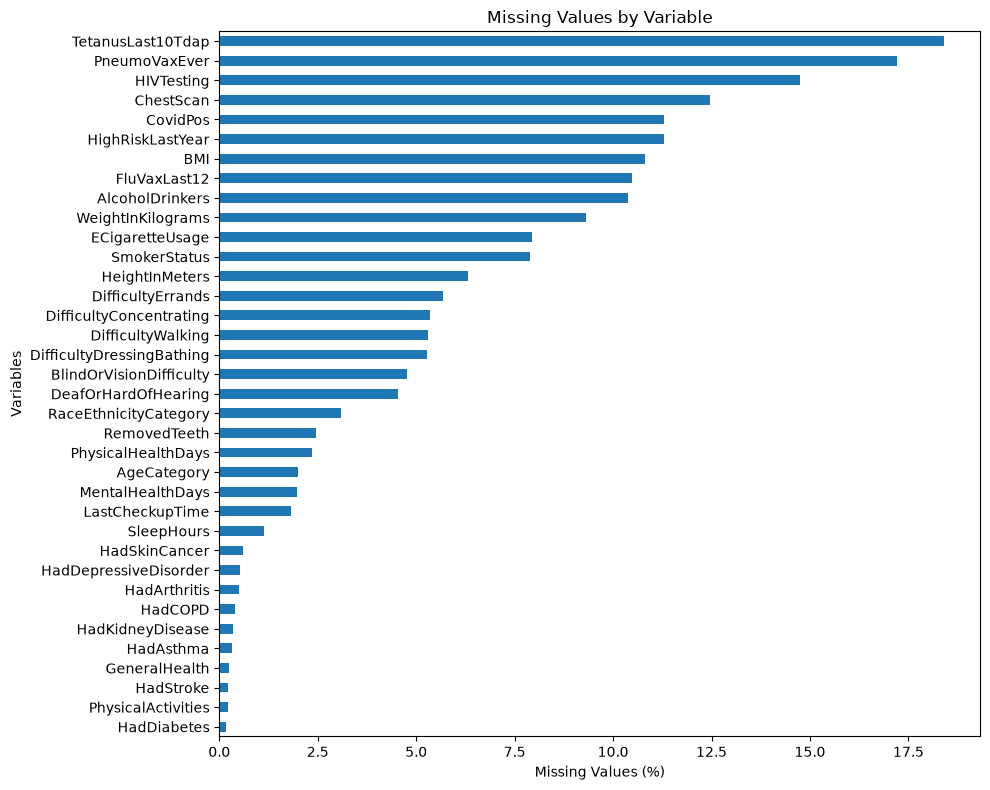

In [8]:
plt.figure(figsize=(10, 8))

missing_percent[missing_percent > 0].sort_values().plot(
    kind="barh"
)

plt.title("Missing Values by Variable")
plt.xlabel("Missing Values (%)")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

### Missing-value overview — interpretation

Missingness is uneven across features. The highest missingness levels previously observed include `TetanusLast10Tdap` (18.40%), `PneumoVaxEver` (17.20%), and `BMI` (10.82%). This means that preprocessing decisions may need to differ by feature.

Missingness percentages describe data availability; they do not reveal why values are missing. The missingness pattern should therefore be considered during modelling, without assuming that missingness is random or automatically informative.

In [9]:
df.groupby("AgeCategory")["BMI"].apply(
    lambda x: x.isnull().sum()
)

AgeCategory
Age 18 to 24       2133
Age 25 to 29       1871
Age 30 to 34       2335
Age 35 to 39       2347
Age 40 to 44       2310
Age 45 to 49       2141
Age 50 to 54       2446
Age 55 to 59       2567
Age 60 to 64       3017
Age 65 to 69       2919
Age 70 to 74       2593
Age 75 to 79       1782
Age 80 or older    1948
Name: BMI, dtype: int64

In [10]:
bmi_missing_by_age = df.groupby("AgeCategory", observed=False)["BMI"].apply(
    lambda x: x.isnull().mean() * 100
)

bmi_missing_by_age

AgeCategory
Age 18 to 24       11.425970
Age 25 to 29       12.204827
Age 30 to 34       13.023593
Age 35 to 39       11.802866
Age 40 to 44       11.119134
Age 45 to 49       10.786438
Age 50 to 54       10.538561
Age 55 to 59       10.073382
Age 60 to 64        9.770394
Age 65 to 69        8.950144
Age 70 to 74        8.609755
Age 75 to 79        7.933045
Age 80 or older     7.873252
Name: BMI, dtype: float64

In [11]:

df.groupby("Sex")["BMI"].apply(
    lambda x: x.isnull().mean() * 100
)

Sex
Female    13.9098
Male       7.3325
Name: BMI, dtype: float64

In [12]:
df.groupby("State")["BMI"].apply(
    lambda x: x.isnull().mean() * 100
).sort_values(ascending=False)

State
New Jersey              17.959895
Connecticut             15.947189
Indiana                 15.651102
New York                15.645983
Texas                   13.777687
Rhode Island            13.472533
California              13.243385
Michigan                12.826739
Maryland                12.746398
Georgia                 12.564544
Washington              12.554969
South Carolina          12.356199
New Hampshire           12.084851
Arkansas                11.792323
Massachusetts           11.755486
Florida                 11.596693
Vermont                 11.504569
Utah                    11.386284
District of Columbia    10.971223
Delaware                10.869565
Wisconsin               10.620480
Tennessee               10.465753
Colorado                10.243752
North Carolina           9.945980
Alaska                   9.832793
Virginia                 9.800618
Ohio                     9.669749
Iowa                     9.645574
Arizona                  9.616494
Idaho   

In [13]:
df[["BMI", "HeightInMeters", "WeightInKilograms"]].isnull().sum()

BMI                  33328
HeightInMeters       19420
WeightInKilograms    28728
dtype: int64

In [14]:
missing_overlap = pd.crosstab(
    df["BMI"].isnull(),
    df["HeightInMeters"].isnull()
)

missing_overlap

HeightInMeters,False,True
BMI,,
False,274752,0
True,13908,19420


In [15]:
pd.crosstab(
    df["BMI"].isnull(),
    df["WeightInKilograms"].isnull()
)

WeightInKilograms,False,True
BMI,,
False,274752,0
True,4600,28728


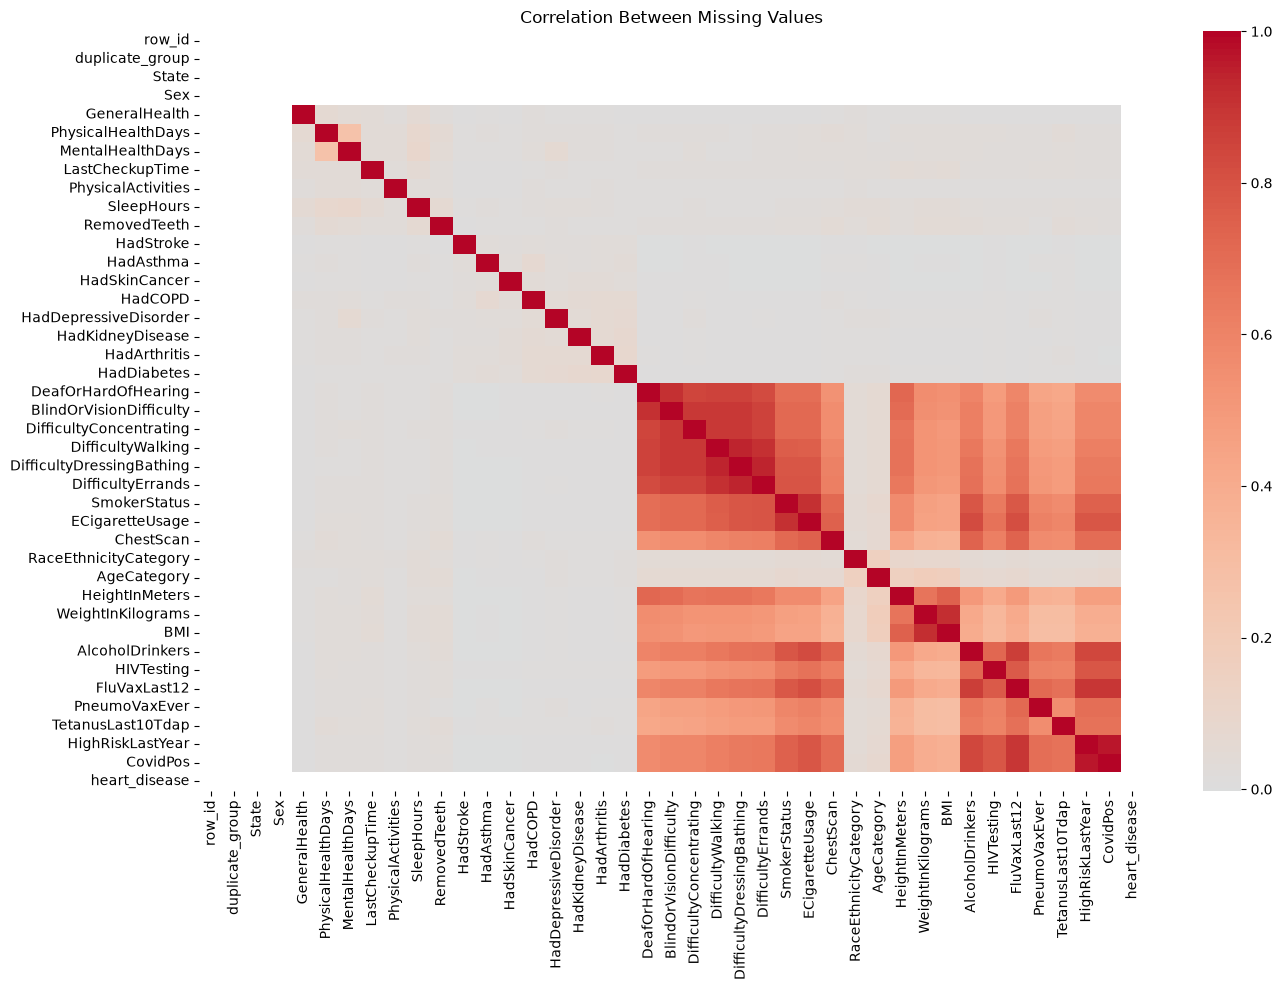

In [16]:
missing_corr = df.isnull().corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    missing_corr,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Between Missing Values")
plt.tight_layout()
plt.show()

### Missingness across demographic groups and variables

The following checks examine BMI availability across age, sex and state groups, the overlap of missing values between features, and correlations between missingness indicators.

In [17]:
bmi_missing_summary = df.groupby(
    df["BMI"].isna()
)["heart_disease"].agg(["count", "mean"])

bmi_missing_summary.index = [
    "BMI Available",
    "BMI Missing"
]

bmi_missing_summary["heart_disease_percent"] = (
    bmi_missing_summary["mean"] * 100
)

display(bmi_missing_summary.round(2))

,count,mean,heart_disease_percent
BMI Available,274752,0.09,9.29
BMI Missing,33328,0.07,6.87


## 3. Target distribution

Before comparing predictors, we examine the balance of the target variable. This is important because an imbalanced target can make accuracy alone misleading during model evaluation.

In [18]:
df["heart_disease"].value_counts()

heart_disease
0    280254
1     27826
Name: count, dtype: int64

In [19]:
df["heart_disease"].value_counts(normalize=True) * 100

heart_disease
0    90.96793
1     9.03207
Name: proportion, dtype: float64

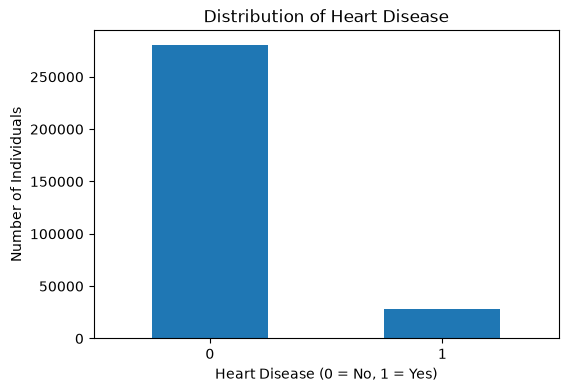

In [20]:
df["heart_disease"].value_counts().plot(
    kind="bar",
    rot=0,
    figsize=(6, 4)
)

plt.title("Distribution of Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Individuals")
plt.show()

### Target distribution — interpretation

The target is imbalanced: approximately **90.97%** of records are in the no-heart-disease group and **9.03%** are in the heart-disease group.

Member 3 should therefore report class-sensitive evaluation metrics, such as recall, precision, F1-score and PR-AUC, alongside the confusion matrix and accuracy.

## 4. Demographic feature analysis

This section compares the observed heart disease percentage across age categories and sex. Percentages are descriptive and should be interpreted with the group counts in mind.

In [21]:
df["AgeCategory"].value_counts(dropna=False)

AgeCategory
Age 65 to 69       32614
Age 60 to 64       30879
Age 70 to 74       30117
Age 55 to 59       25483
Age 80 or older    24742
Age 50 to 54       23210
Age 75 to 79       22463
Age 40 to 44       20775
Age 35 to 39       19885
Age 45 to 49       19849
Age 18 to 24       18668
Age 30 to 34       17929
Age 25 to 29       15330
NaN                 6136
Name: count, dtype: int64

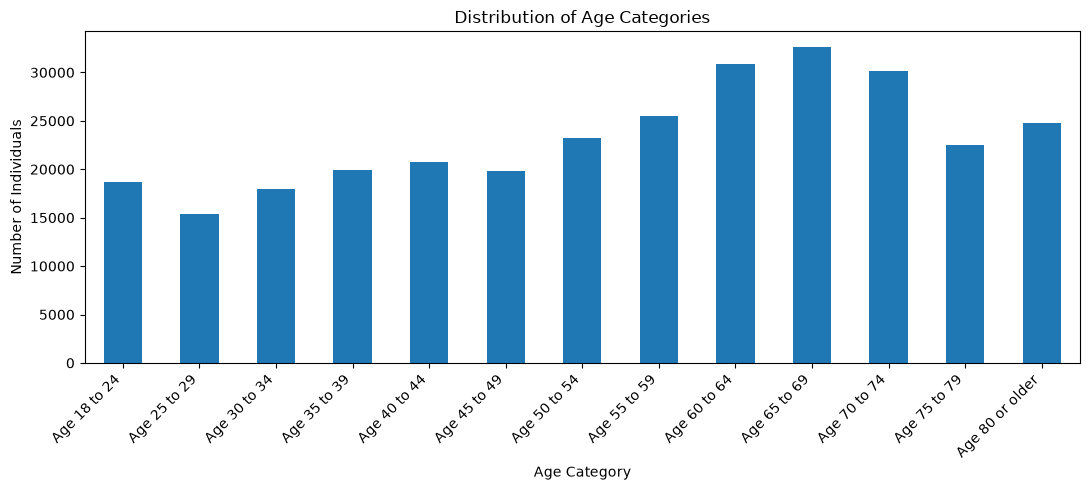

In [22]:
age_order = [
    "Age 18 to 24",
    "Age 25 to 29",
    "Age 30 to 34",
    "Age 35 to 39",
    "Age 40 to 44",
    "Age 45 to 49",
    "Age 50 to 54",
    "Age 55 to 59",
    "Age 60 to 64",
    "Age 65 to 69",
    "Age 70 to 74",
    "Age 75 to 79",
    "Age 80 or older"
]

age_counts = df["AgeCategory"].value_counts().reindex(age_order)

age_counts.plot(kind="bar", figsize=(11, 5))

plt.title("Distribution of Age Categories")
plt.xlabel("Age Category")
plt.ylabel("Number of Individuals")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

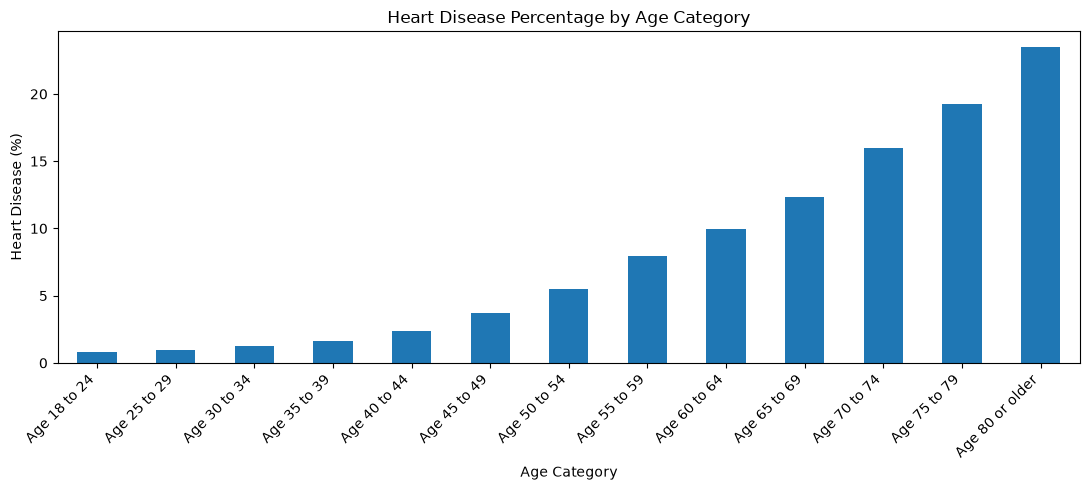

In [23]:
age_hd = df.groupby("AgeCategory", observed=False)["heart_disease"].mean() * 100

age_hd = age_hd.reindex(age_order)

age_hd.plot(kind="bar", figsize=(11, 5))

plt.title("Heart Disease Percentage by Age Category")
plt.xlabel("Age Category")
plt.ylabel("Heart Disease (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [24]:
age_summary = df.groupby("AgeCategory", observed=False)["heart_disease"].agg(
    ["mean", "count"]
)

age_summary["heart_disease_percent"] = age_summary["mean"] * 100
age_summary.reindex(age_order)[["count", "heart_disease_percent"]]

,count,heart_disease_percent
AgeCategory,,
Age 18 to 24,18668,0.776730
Age 25 to 29,15330,0.991520
Age 30 to 34,17929,1.232640
Age 35 to 39,19885,1.639427
Age 40 to 44,20775,2.353791
Age 45 to 49,19849,3.713033
Age 50 to 54,23210,5.523481
Age 55 to 59,25483,7.950398
Age 60 to 64,30879,9.990609


### Age — interpretation

The observed heart disease percentage increases across older age categories: approximately **0.78%** among ages 18–24, **5.52%** among ages 50–54, **12.35%** among ages 65–69, and **23.48%** among those aged 80 or older.

Age shows a clear descriptive association with the target and is a strong candidate for evaluation in the modelling stage. This pattern does not imply that age alone explains the differences.

In [25]:
sex_summary = df.groupby("Sex")["heart_disease"].agg(
    ["count", "mean"]
)

sex_summary["heart_disease_percent"] = sex_summary["mean"] * 100

sex_summary

,count,mean,heart_disease_percent
Sex,,,
Female,163259,0.071224,7.122425
Male,144821,0.111848,11.184842


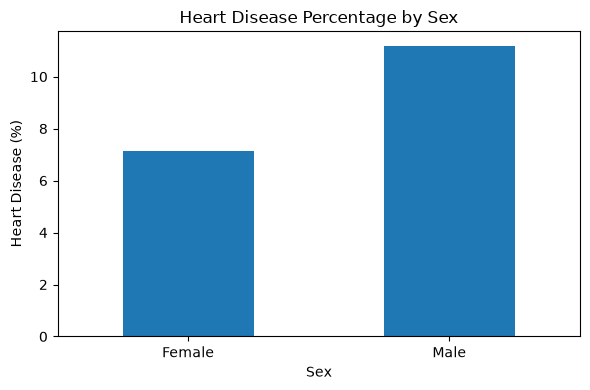

In [26]:
sex_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(6, 4),
    rot=0
)

plt.title("Heart Disease Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()


### Sex — interpretation

The overall heart disease percentage differs by sex in the training data: approximately **7.12%** among females and **11.18%** among males.

Sex may be retained as a candidate feature for modelling. Its association should also be interpreted alongside age because the age distribution may differ between sex groups.

## 5. Health and lifestyle feature analysis

The following subsections examine each feature separately. For each variable, the code reports its distribution and/or the heart disease percentage across its categories. These are unadjusted descriptive comparisons.

### Diabetes status

In [27]:
diabetes_summary = df.groupby("HadDiabetes")["heart_disease"].agg(
    ["count", "mean"]
)

diabetes_summary["heart_disease_percent"] = (
    diabetes_summary["mean"] * 100
)

diabetes_summary

,count,mean,heart_disease_percent
HadDiabetes,,,
No,255555,0.068737,6.873667
"No, pre-diabetes or borderline diabetes",7024,0.126139,12.613895
Yes,42281,0.217190,21.718975
"Yes, but only during pregnancy (female)",2696,0.047107,4.710682


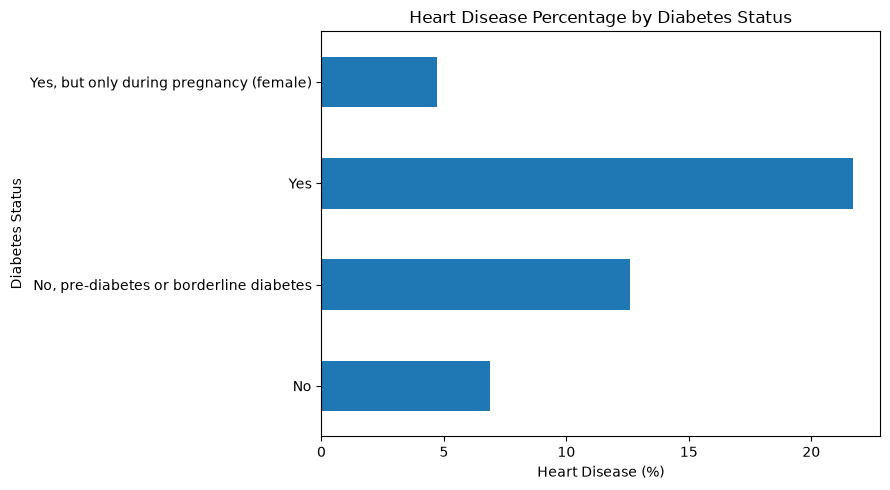

In [28]:
diabetes_summary["heart_disease_percent"].plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Heart Disease Percentage by Diabetes Status")
plt.xlabel("Heart Disease (%)")
plt.ylabel("Diabetes Status")
plt.tight_layout()
plt.show()

**Interpretation:** The observed heart disease percentage was **6.87%** among participants reporting no diabetes, **12.61%** among those reporting borderline or prediabetes, and **21.72%** among those reporting diabetes. This is a clear descriptive difference. `HadDiabetes` is a candidate feature, but its contribution should be evaluated in the model alongside age and other health conditions.

### General health

In [29]:
df["GeneralHealth"].value_counts(dropna=False)

GeneralHealth
Very good    103246
Good          99394
Excellent     49973
Fair          41388
Poor          13334
NaN             745
Name: count, dtype: int64

In [30]:
health_summary = df.groupby("GeneralHealth")["heart_disease"].agg(
    ["count", "mean"]
)

health_summary["heart_disease_percent"] = health_summary["mean"] * 100

health_summary

,count,mean,heart_disease_percent
GeneralHealth,,,
Excellent,49973,0.023953,2.395293
Fair,41388,0.191650,19.164975
Good,99394,0.093990,9.398958
Poor,13334,0.325709,32.570871
Very good,103246,0.047372,4.737230


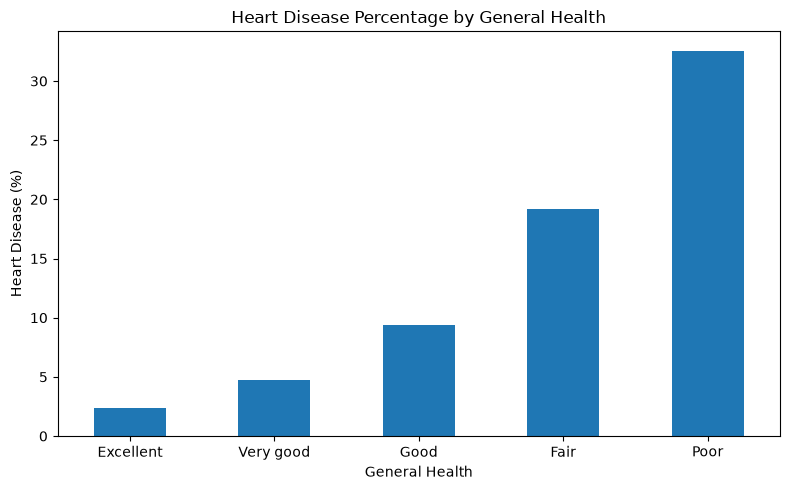

In [31]:
health_order = [
    "Excellent",
    "Very good",
    "Good",
    "Fair",
    "Poor"
]

health_summary["heart_disease_percent"].reindex(health_order).plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Heart Disease Percentage by General Health")
plt.xlabel("General Health")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()

**Interpretation:** Heart disease percentage increased as self-reported general health became poorer: **2.40%** for Excellent, **4.74%** for Very good, **9.40%** for Good, **19.16%** for Fair, and **32.57%** for Poor. `GeneralHealth` is a useful candidate feature. Because it is self-reported and may summarize several underlying conditions, it should be interpreted as an overall health indicator rather than a causal factor.

### Smoking status

In [32]:
df["SmokerStatus"].value_counts(dropna=False)

SmokerStatus
Never smoked                             170841
Former smoker                             78630
Current smoker - now smokes every day     24720
NaN                                       24288
Current smoker - now smokes some days      9601
Name: count, dtype: int64

In [33]:
smoking_summary = df.groupby("SmokerStatus")["heart_disease"].agg(
    ["count", "mean"]
)

smoking_summary["heart_disease_percent"] = (
    smoking_summary["mean"] * 100
)

smoking_summary

,count,mean,heart_disease_percent
SmokerStatus,,,
Current smoker - now smokes every day,24720,0.122816,12.281553
Current smoker - now smokes some days,9601,0.097386,9.738569
Former smoker,78630,0.135902,13.590233
Never smoked,170841,0.065459,6.545853


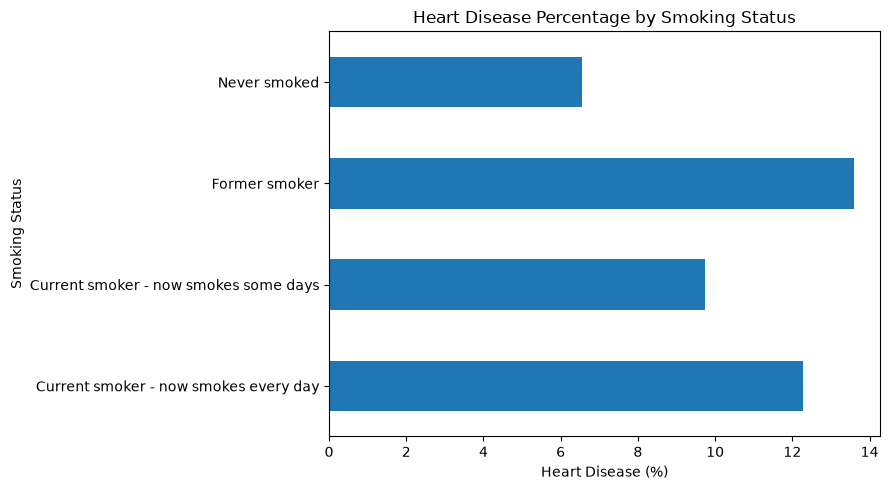

In [34]:
smoking_summary["heart_disease_percent"].plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Heart Disease Percentage by Smoking Status")
plt.xlabel("Heart Disease (%)")
plt.ylabel("Smoking Status")
plt.tight_layout()
plt.show()

**Interpretation:** The observed percentages were **6.55%** among never-smokers, **12.28%** among daily smokers, **9.74%** among people who smoke some days, and **13.59%** among former smokers. The higher rate among former smokers may partly reflect age or health-related changes in smoking behaviour. Keep `SmokerStatus` as a candidate feature and assess it with age-stratified or model-based analysis.

### Physical activity

In [35]:
activity_summary = df.groupby("PhysicalActivities")["heart_disease"].agg(
    ["count", "mean"]
)

activity_summary["heart_disease_percent"] = activity_summary["mean"] * 100

activity_summary

,count,mean,heart_disease_percent
PhysicalActivities,,,
No,73303,0.140881,14.088100
Yes,234094,0.074333,7.433339


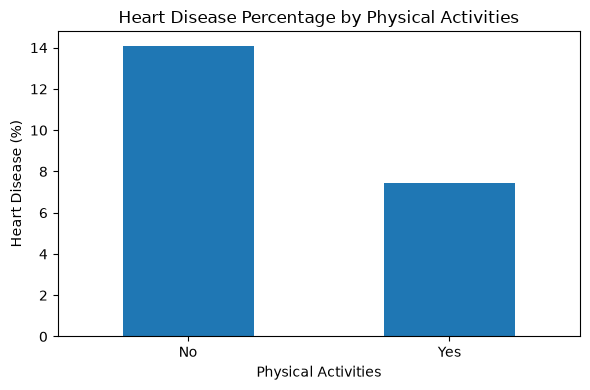

In [36]:
activity_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(6, 4),
    rot=0
)

plt.title("Heart Disease Percentage by Physical Activities")
plt.xlabel("Physical Activities")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()

**Interpretation:** Participants reporting no physical activity had a higher observed heart disease percentage (**14.09%**) than those reporting physical activity (**7.43%**). This is an unadjusted association; age and existing health conditions may influence both activity and heart disease status.

### Sleep duration

In [37]:
df["SleepHours"].describe()

count    304555.000000
mean          7.025125
std           1.497223
min           1.000000
25%           6.000000
50%           7.000000
75%           8.000000
max          24.000000
Name: SleepHours, dtype: float64

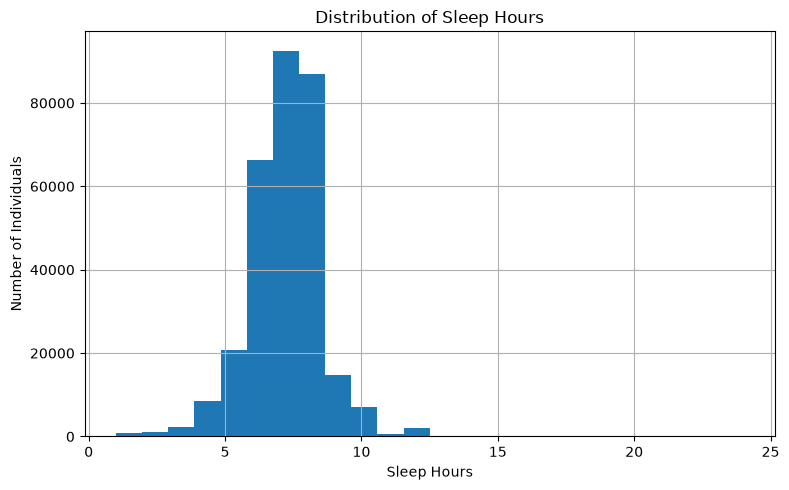

In [38]:
df["SleepHours"].hist(bins=24, figsize=(8, 5))

plt.title("Distribution of Sleep Hours")
plt.xlabel("Sleep Hours")
plt.ylabel("Number of Individuals")
plt.tight_layout()
plt.show()

In [39]:
sleep_summary = df.groupby("SleepHours")["heart_disease"].agg(
    ["count", "mean"]
)

sleep_summary["heart_disease_percent"] = sleep_summary["mean"] * 100

sleep_summary

,count,mean,heart_disease_percent
SleepHours,,,
1.0,771,0.111543,11.154345
2.0,1053,0.186135,18.613485
3.0,2227,0.185002,18.500225
4.0,8456,0.152909,15.290918
5.0,20848,0.106005,10.600537
6.0,66326,0.085276,8.527576
7.0,92550,0.067650,6.764992
8.0,86867,0.089171,8.917080
9.0,14652,0.110906,11.090636


In [40]:
df["SleepGroup"] = pd.cut(
    df["SleepHours"],
    bins=[0, 6, 9, 25],
    labels=["Less than 6", "6 to 8", "More than 8"],
    right=False
)

sleep_group_for_summary = df["SleepGroup"].astype("object").fillna("Missing")
sleep_group_summary = (
    df.assign(SleepGroup=sleep_group_for_summary)
      .groupby("SleepGroup", dropna=False)["heart_disease"]
      .agg(Total="count", Heart_Disease_Cases="sum", Heart_Disease_Rate="mean")
)
sleep_group_summary["Heart_Disease_Rate"] *= 100
print(sleep_group_summary.round(2).to_string())

              Total  Heart_Disease_Cases  Heart_Disease_Rate
SleepGroup                                                  
6 to 8       245743                19663                8.00
Less than 6   33355                 4197               12.58
Missing        3525                  498               14.13
More than 8   25457                 3468               13.62


In [41]:
# Sleep duration: inspect the non-linear (potentially U-shaped) pattern.
sleep_group_summary = (
    df.assign(SleepGroup=df["SleepGroup"].astype("object").fillna("Missing"))
      .groupby("SleepGroup", dropna=False)["heart_disease"]
      .agg(Total="count", Heart_Disease_Cases="sum", Heart_Disease_Rate="mean")
)
sleep_group_summary["Heart_Disease_Rate"] *= 100
print("Heart disease rate by sleep-duration group:")
print(sleep_group_summary.round(2).to_string())

Heart disease rate by sleep-duration group:
              Total  Heart_Disease_Cases  Heart_Disease_Rate
SleepGroup                                                  
6 to 8       245743                19663                8.00
Less than 6   33355                 4197               12.58
Missing        3525                  498               14.13
More than 8   25457                 3468               13.62


**Interpretation:** The sleep pattern is not simply linear. The heart disease percentage was **12.58%** for the shorter-sleep group (≤5 hours), **8.00%** for 6–8 hours, and **13.62%** for more than 8 hours. The middle group had the lowest observed percentage, while both shorter and longer sleep groups had higher percentages.

This suggests a potentially U-shaped pattern. `SleepHours` should not automatically be treated as having a linear relationship with the target; Member 3 can compare a continuous representation with grouped or nonlinear representations.

### Body mass index (BMI)

In [42]:
df["BMI"].describe()

count    274752.000000
mean         28.526866
std           6.552425
min          12.060000
25%          24.130000
50%          27.440000
75%          31.750000
max          99.340000
Name: BMI, dtype: float64

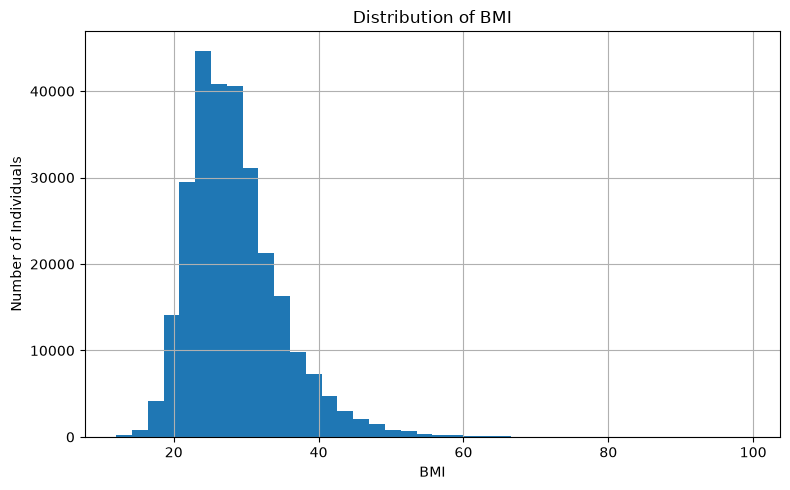

In [43]:
plt.figure(figsize=(8, 5))

df["BMI"].hist(bins=40)

plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Number of Individuals")
plt.tight_layout()
plt.show()

In [44]:
Q1 = df["BMI"].quantile(0.25)
Q3 = df["BMI"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = df[
    (df["BMI"] < lower_bound) |
    (df["BMI"] > upper_bound)
]

print("Number of potential outliers:", len(outliers))

Lower bound: 12.699999999999998
Upper bound: 43.18
Number of potential outliers: 8544


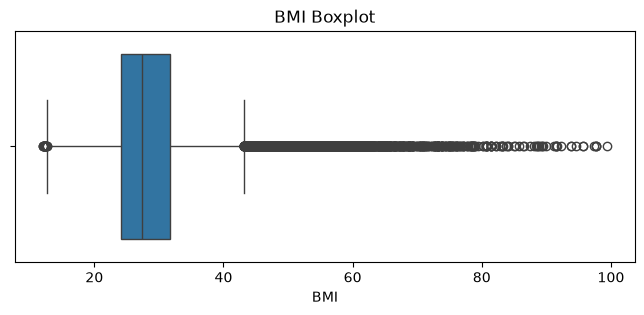

In [45]:
plt.figure(figsize=(8, 3))

sns.boxplot(x=df["BMI"])

plt.title("BMI Boxplot")
plt.xlabel("BMI")
plt.show()

In [46]:
df["BMI_Group"] = pd.cut(
    df["BMI"],
    bins=[0, 18.5, 25, 30, 35, 40, float("inf")],
    labels=[
        "Underweight",
        "Normal",
        "Overweight",
        "Obesity Class I",
        "Obesity Class II",
        "Obesity Class III"
    ],
    right=False
)

bmi_summary = df.groupby(
    "BMI_Group",
    observed=False
)["heart_disease"].agg(["count", "mean"])

bmi_summary["heart_disease_percent"] = (
    bmi_summary["mean"] * 100
)

bmi_summary

,count,mean,heart_disease_percent
BMI_Group,,,
Underweight,4695,0.086049,8.604899
Normal,81150,0.072545,7.254467
Overweight,97109,0.094790,9.479039
Obesity Class I,53569,0.108029,10.802890
Obesity Class II,22731,0.112446,11.244556
Obesity Class III,15498,0.109563,10.956252


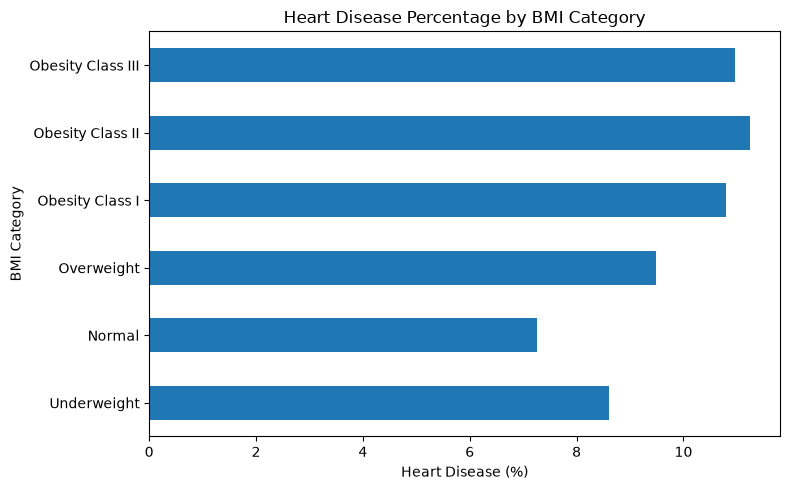

In [47]:
bmi_summary["heart_disease_percent"].plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Heart Disease Percentage by BMI Category")
plt.xlabel("Heart Disease (%)")
plt.ylabel("BMI Category")
plt.tight_layout()
plt.show()

**Interpretation:** The observed heart disease percentages were **8.60%** for underweight (n=4,695), **7.25%** for normal BMI, **9.48%** for overweight, **10.80%** for obesity class I, **11.24%** for obesity class II, and **10.96%** for obesity class III. The percentage generally rises across the categories above normal BMI, although the pattern is not strictly increasing at the highest category.

BMI is a candidate anthropometric feature. Because BMI is derived from height and weight, avoid automatically including all three without checking redundancy and validation performance.

### Physical health days

In [48]:
df["PhysicalHealthDays"].describe()

count    300802.000000
mean          4.312348
std           8.646601
min           0.000000
25%           0.000000
50%           0.000000
75%           3.000000
max          30.000000
Name: PhysicalHealthDays, dtype: float64

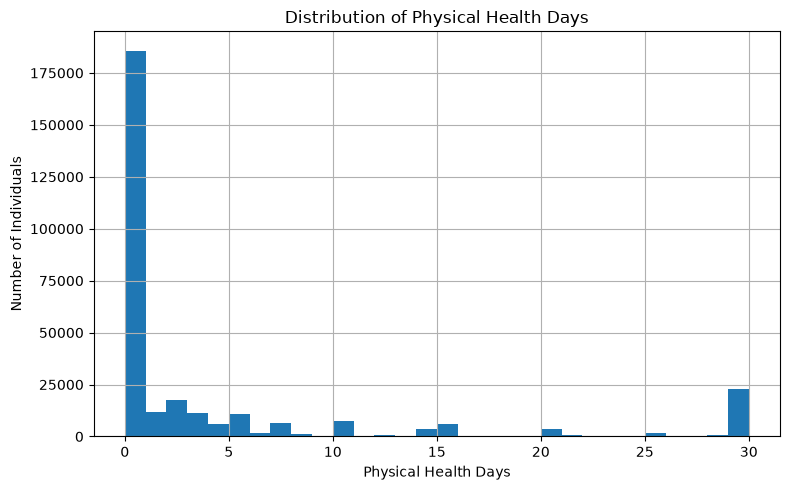

In [49]:
plt.figure(figsize=(8, 5))

df["PhysicalHealthDays"].hist(bins=30)

plt.title("Distribution of Physical Health Days")
plt.xlabel("Physical Health Days")
plt.ylabel("Number of Individuals")
plt.tight_layout()
plt.show()

In [50]:
Q1 = df["PhysicalHealthDays"].quantile(0.25)
Q3 = df["PhysicalHealthDays"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper bound:", upper_bound)

outliers = df[df["PhysicalHealthDays"] > upper_bound]

print("Potential outliers:", len(outliers))

Q1: 0.0
Q3: 3.0
IQR: 3.0
Upper bound: 7.5
Potential outliers: 49641


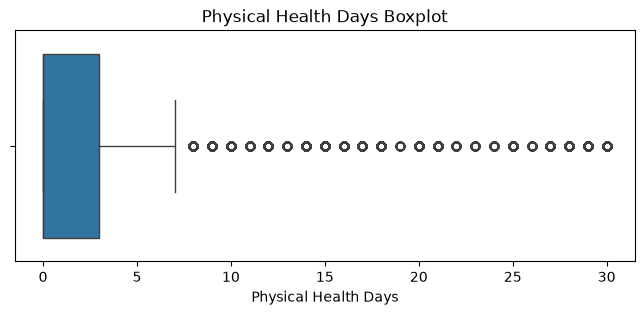

In [51]:
plt.figure(figsize=(8, 3))

sns.boxplot(x=df["PhysicalHealthDays"])

plt.title("Physical Health Days Boxplot")
plt.xlabel("Physical Health Days")
plt.show()

In [52]:
df["PhysicalHealthGroup"] = pd.cut(
    df["PhysicalHealthDays"],
    bins=[-1, 0, 7, 30],
    labels=["0 days", "1-7 days", "8-30 days"]
)

physical_summary = df.groupby(
    "PhysicalHealthGroup",
    observed=False
)["heart_disease"].agg(["count", "mean"])

physical_summary["heart_disease_percent"] = (
    physical_summary["mean"] * 100
)

physical_summary

,count,mean,heart_disease_percent
PhysicalHealthGroup,,,
0 days,185732,0.063882,6.388237
1-7 days,65429,0.081814,8.181387
8-30 days,49641,0.192522,19.252231


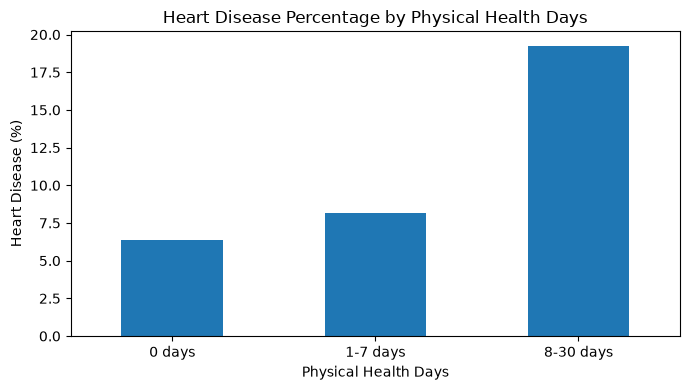

In [53]:
physical_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Heart Disease Percentage by Physical Health Days")
plt.xlabel("Physical Health Days")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()

**Interpretation:** The observed heart disease percentage increases with more days of poor physical health: approximately **6.39%** for 0 days, **8.18%** for 1–7 days, and **19.25%** for 8–30 days. This feature may capture broader health burden. The distribution is highly concentrated at zero, so its modelling representation should be assessed rather than assuming a normal distribution.

### Mental health days

In [54]:
df["MentalHealthDays"].describe()

count    302038.000000
mean          4.361640
std           8.356918
min           0.000000
25%           0.000000
50%           0.000000
75%           5.000000
max          30.000000
Name: MentalHealthDays, dtype: float64

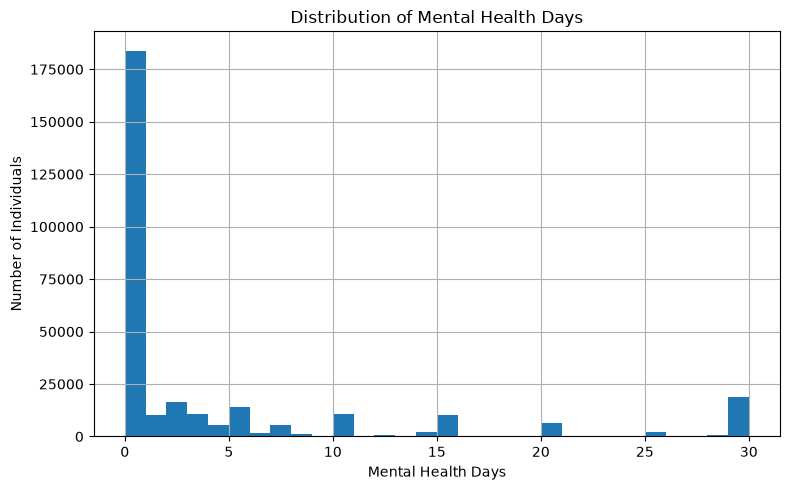

In [55]:
plt.figure(figsize=(8, 5))

df["MentalHealthDays"].hist(bins=30)

plt.title("Distribution of Mental Health Days")
plt.xlabel("Mental Health Days")
plt.ylabel("Number of Individuals")
plt.tight_layout()
plt.show()

In [56]:
Q1 = df["MentalHealthDays"].quantile(0.25)
Q3 = df["MentalHealthDays"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

outliers = df[df["MentalHealthDays"] > upper_bound]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper bound:", upper_bound)
print("Potential outliers:", len(outliers))

Q1: 0.0
Q3: 5.0
IQR: 5.0
Upper bound: 12.5
Potential outliers: 41697


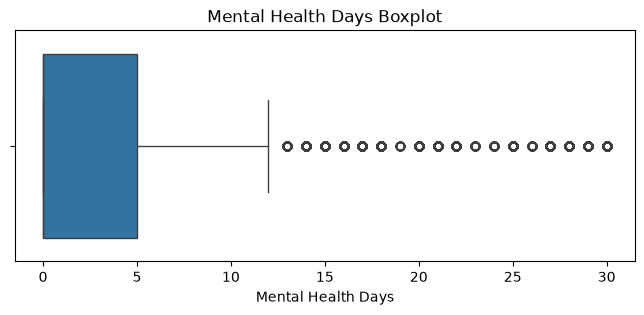

In [57]:
plt.figure(figsize=(8, 3))

sns.boxplot(x=df["MentalHealthDays"])

plt.title("Mental Health Days Boxplot")
plt.xlabel("Mental Health Days")
plt.show()

In [58]:
df["MentalHealthGroup"] = pd.cut(
    df["MentalHealthDays"],
    bins=[-1, 0, 7, 30],
    labels=["0 days", "1-7 days", "8-30 days"]
)

mental_summary = df.groupby(
    "MentalHealthGroup",
    observed=False
)["heart_disease"].agg(["count", "mean"])

mental_summary["heart_disease_percent"] = (
    mental_summary["mean"] * 100
)

mental_summary

,count,mean,heart_disease_percent
MentalHealthGroup,,,
0 days,183886,0.092639,9.263892
1-7 days,63448,0.066306,6.630627
8-30 days,54704,0.106537,10.653700


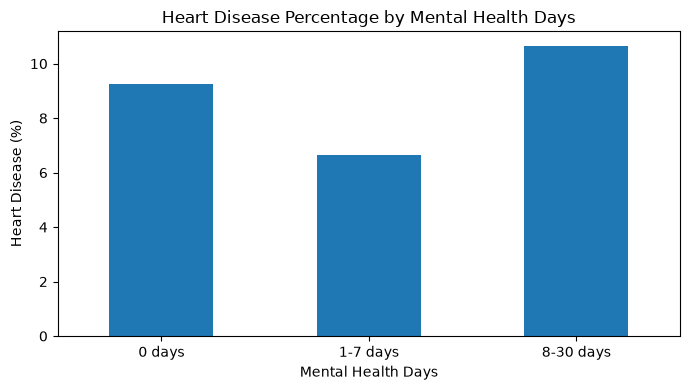

In [59]:
mental_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Heart Disease Percentage by Mental Health Days")
plt.xlabel("Mental Health Days")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()

**Interpretation:** The relationship is not monotonic. The observed percentage was approximately **9.26%** for 0 days, **6.63%** for 1–7 days, and **10.65%** for 8–30 days. The differences are smaller and less consistent than those observed for physical health days. Interpret this feature cautiously and evaluate its contribution during modelling.

### Teeth removed

In [60]:
df["RemovedTeeth"].value_counts(dropna=False)

RemovedTeeth
None of them              162346
1 to 5                     89358
6 or more, but not all     31325
All                        17452
NaN                         7599
Name: count, dtype: int64

In [61]:
teeth_summary = df.groupby("RemovedTeeth")["heart_disease"].agg(
    ["count", "mean"]
)

teeth_summary["heart_disease_percent"] = (
    teeth_summary["mean"] * 100
)

teeth_summary

,count,mean,heart_disease_percent
RemovedTeeth,,,
1 to 5,89358,0.100237,10.023725
"6 or more, but not all",31325,0.188029,18.802873
All,17452,0.242780,24.278020
None of them,162346,0.047257,4.725709


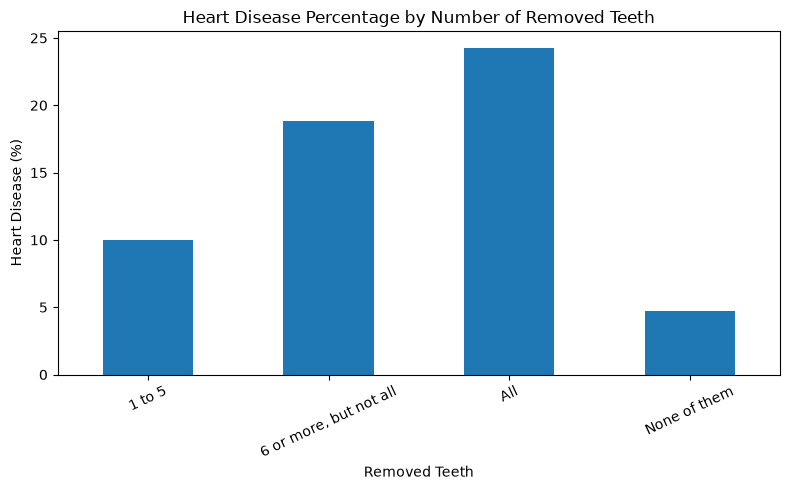

In [62]:
teeth_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(8, 5),
    rot=25
)

plt.title("Heart Disease Percentage by Number of Removed Teeth")
plt.xlabel("Removed Teeth")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()

**Interpretation:** Heart disease percentage increased across the tooth-loss categories: **4.73%** among participants reporting no teeth removed, **10.02%** for 1–5 teeth, **18.80%** for 6 or more but not all, and **24.28%** for all teeth removed. This is a strong descriptive gradient, but it may reflect age, general health or access-to-care differences rather than a direct relationship.

### Other health conditions

In [63]:
df["HadStroke"].value_counts(dropna=False)

HadStroke
No     294284
Yes     13099
NaN       697
Name: count, dtype: int64

In [64]:
stroke_summary = df.groupby("HadStroke")["heart_disease"].agg(
    ["count", "mean"]
)

stroke_summary["heart_disease_percent"] = (
    stroke_summary["mean"] * 100
)

stroke_summary

,count,mean,heart_disease_percent
HadStroke,,,
No,294284,0.077745,7.774463
Yes,13099,0.362089,36.208871


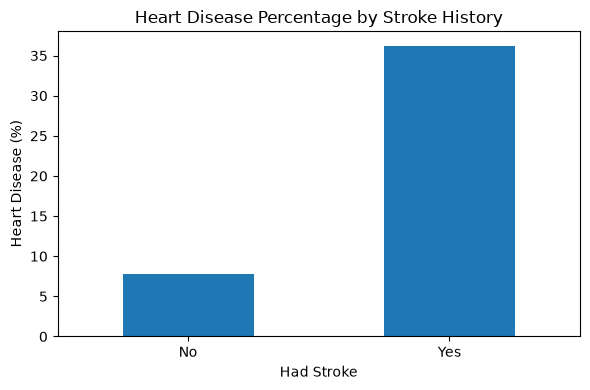

In [65]:
stroke_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(6, 4),
    rot=0
)

plt.title("Heart Disease Percentage by Stroke History")
plt.xlabel("Had Stroke")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()

In [66]:
df["HadKidneyDisease"].value_counts(dropna=False)

HadKidneyDisease
No     293046
Yes     13956
NaN      1078
Name: count, dtype: int64

In [67]:
kidney_summary = df.groupby("HadKidneyDisease")["heart_disease"].agg(
    ["count", "mean"]
)

kidney_summary["heart_disease_percent"] = (
    kidney_summary["mean"] * 100
)

kidney_summary

,count,mean,heart_disease_percent
HadKidneyDisease,,,
No,293046,0.080151,8.015124
Yes,13956,0.293064,29.306392


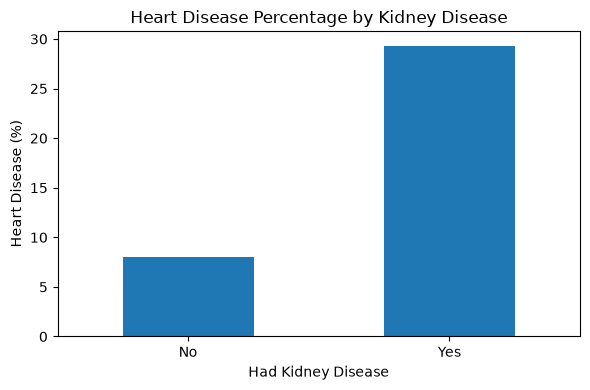

In [68]:
kidney_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(6, 4),
    rot=0
)

plt.title("Heart Disease Percentage by Kidney Disease")
plt.xlabel("Had Kidney Disease")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()

In [69]:
df["HadArthritis"].value_counts(dropna=False)

HadArthritis
No     202009
Yes    104530
NaN      1541
Name: count, dtype: int64

In [70]:
arthritis_summary = df.groupby("HadArthritis")["heart_disease"].agg(
    ["count", "mean"]
)

arthritis_summary["heart_disease_percent"] = (
    arthritis_summary["mean"] * 100
)

arthritis_summary

,count,mean,heart_disease_percent
HadArthritis,,,
No,202009,0.054968,5.496785
Yes,104530,0.158576,15.857649


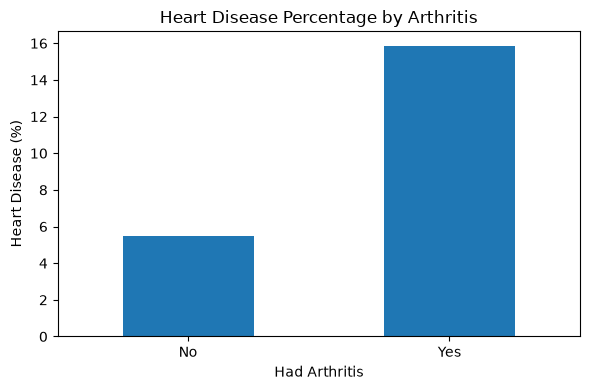

In [71]:
arthritis_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(6, 4),
    rot=0
)

plt.title("Heart Disease Percentage by Arthritis")
plt.xlabel("Had Arthritis")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()

In [72]:
df["HadAsthma"].value_counts(dropna=False)

HadAsthma
No     260793
Yes     46303
NaN       984
Name: count, dtype: int64

In [73]:
asthma_summary = df.groupby("HadAsthma")["heart_disease"].agg(
    ["count", "mean"]
)

asthma_summary["heart_disease_percent"] = (
    asthma_summary["mean"] * 100
)

asthma_summary

,count,mean,heart_disease_percent
HadAsthma,,,
No,260793,0.085512,8.551226
Yes,46303,0.116731,11.673110


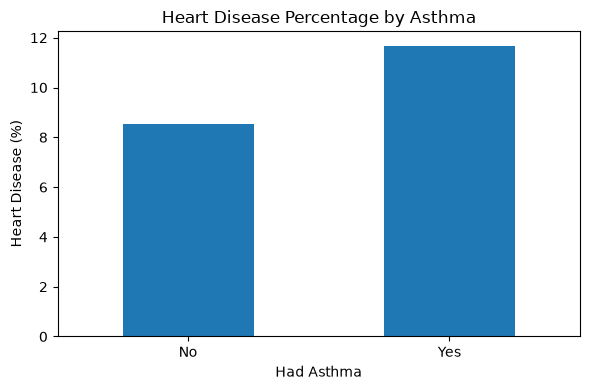

In [74]:
asthma_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(6, 4),
    rot=0
)

plt.title("Heart Disease Percentage by Asthma")
plt.xlabel("Had Asthma")
plt.ylabel("Heart Disease (%)")
plt.tight_layout()
plt.show()

In [75]:
df["HadCOPD"].value_counts(dropna=False)

HadCOPD
No     282471
Yes     24413
NaN      1196
Name: count, dtype: int64

In [76]:
copd_summary = df.groupby("HadCOPD")["heart_disease"].agg(
    ["count", "mean"]
)

copd_summary["heart_disease_percent"] = (
    copd_summary["mean"] * 100
)

copd_summary

,count,mean,heart_disease_percent
HadCOPD,,,
No,282471,0.074840,7.483954
Yes,24413,0.264695,26.469504


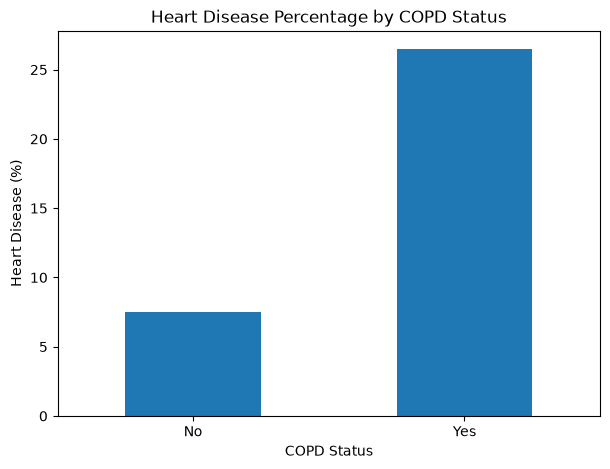

In [77]:
copd_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(7, 5),
    title="Heart Disease Percentage by COPD Status",
    ylabel="Heart Disease (%)",
    xlabel="COPD Status"
)

plt.xticks(rotation=0)
plt.show()

In [78]:
depression_summary = df.groupby("HadDepressiveDisorder")["heart_disease"].agg(
    ["count", "mean"]
)

depression_summary["heart_disease_percent"] = (
    depression_summary["mean"] * 100
)

depression_summary

,count,mean,heart_disease_percent
HadDepressiveDisorder,,,
No,243353,0.084371,8.437126
Yes,63079,0.112621,11.262068


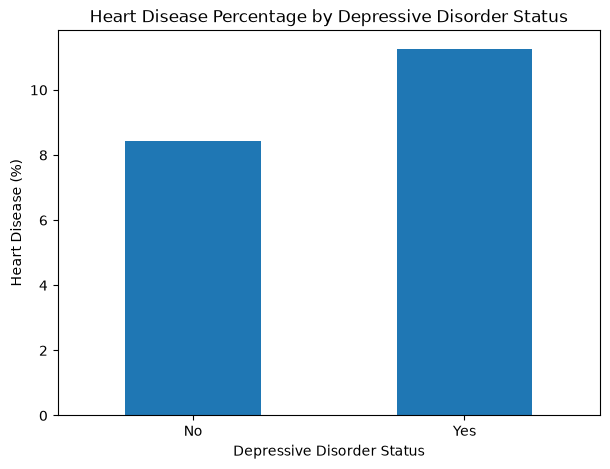

In [79]:
depression_summary["heart_disease_percent"].plot(
    kind="bar",
    figsize=(7, 5),
    title="Heart Disease Percentage by Depressive Disorder Status",
    ylabel="Heart Disease (%)",
    xlabel="Depressive Disorder Status"
)

plt.xticks(rotation=0)
plt.show()

**Interpretation:** Several co-existing health conditions show higher heart disease percentages among participants reporting the condition. Examples include stroke (**36.21%** vs. **7.77%**), kidney disease (**29.31%** vs. **8.02%**), COPD (**26.47%** vs. **7.48%**), and arthritis (**15.86%** vs. **5.50%**). Asthma shows a smaller difference (**11.67%** vs. **8.55%**).

These features may be informative, but they can also reflect age, overall health burden or related diagnoses. They should be evaluated jointly rather than interpreted as independent causal factors.

## 6. Numerical distributions, outliers and measurement checks

This analysis examines numerical distributions, compares selected measures by target group, and flags unusual values for review. An outlier flag is not, by itself, a reason to remove a record.

In [80]:
numeric_vars = [
    "BMI",
    "SleepHours",
    "PhysicalHealthDays",
    "MentalHealthDays"
]

numeric_summary = df.groupby("heart_disease")[numeric_vars].agg(
    ["count", "median", "mean"]
)

display(numeric_summary.round(2))

BMI               SleepHours               \
                count median   mean      count median  mean   
heart_disease                                                 
0              249215  27.37  28.43     277227    7.0  7.02   
1               25537  28.34  29.44      27328    7.0  7.06   

              PhysicalHealthDays              MentalHealthDays               
                           count median  mean            count median  mean  
heart_disease                                                                
0                         274027    0.0  3.84           274968    0.0  4.28  
1                          26775    2.0  9.15            27070    0.0  5.22

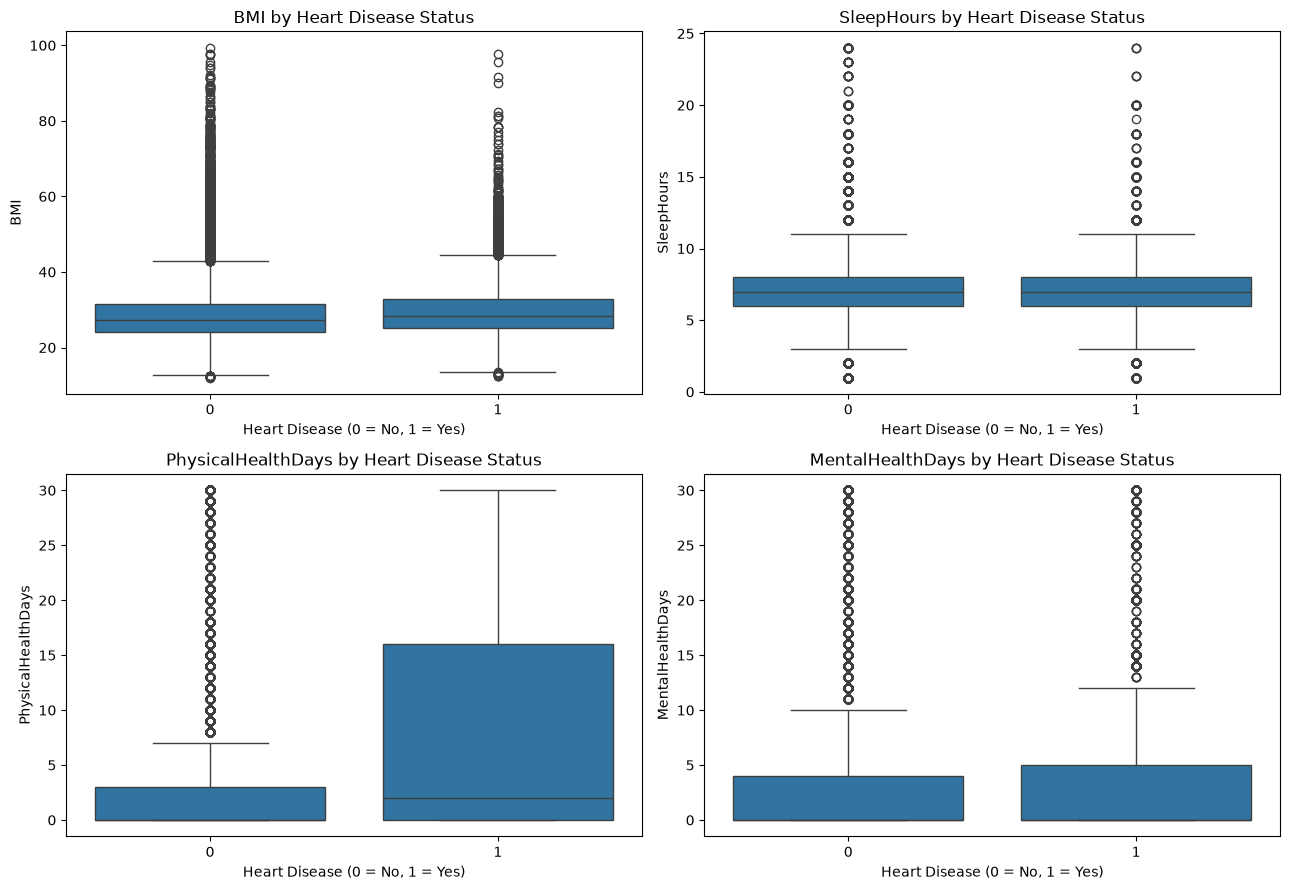

In [81]:
numeric_vars = [
    "BMI",
    "SleepHours",
    "PhysicalHealthDays",
    "MentalHealthDays"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, ax in zip(numeric_vars, axes.flatten()):
    sns.boxplot(
        data=df,
        x="heart_disease",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} by Heart Disease Status")
    ax.set_xlabel("Heart Disease (0 = No, 1 = Yes)")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()


### Interpretation

The boxplots show differences in the distributions of selected numerical variables between individuals with and without heart disease.

- **BMI:** Individuals with heart disease have a slightly higher median BMI (28.34) than those without heart disease (27.37).
- **SleepHours:** Both groups have the same median sleep duration of 7 hours, with largely overlapping distributions.
- **PhysicalHealthDays:** Individuals with heart disease show a higher median (2 days vs. 0 days) and a wider distribution.
- **MentalHealthDays:** Both groups have a median of 0 days, although the mean and spread are slightly higher among individuals with heart disease.

Overall, PhysicalHealthDays shows the clearest distributional difference. These findings are descriptive and do not establish causation.

### Numerical features by heart disease status — interpretation

The boxplots and summary statistics show modest differences in BMI and larger differences in physical health days. Median BMI was approximately **28.34** in the heart-disease group and **27.37** in the no-heart-disease group. Median physical health days were **2** and **0**, respectively. Sleep duration had a median of **7 hours** in both groups, and mental health days had a median of **0** in both groups.

These comparisons describe differences in distributions; they do not establish causality or adjusted predictive importance.

In [82]:
numeric_df = df.select_dtypes(include="number").drop(
    columns=["row_id", "duplicate_group", "heart_disease"],
    errors="ignore"
)

correlation_matrix = numeric_df.corr(method="spearman")

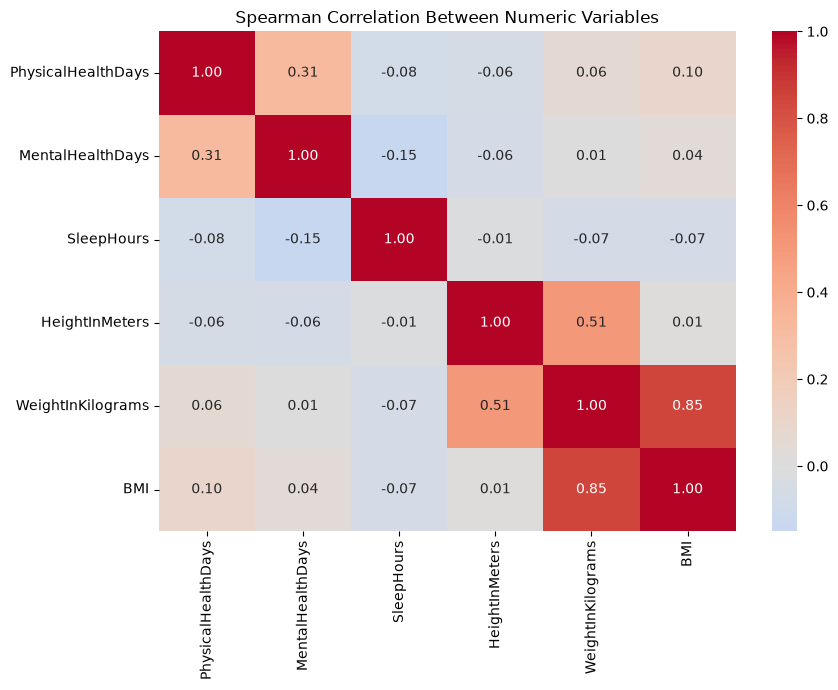

In [83]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Spearman Correlation Between Numeric Variables")
plt.tight_layout()
plt.show()

In [84]:
df[[
    "BMI",
    "SleepHours",
    "PhysicalHealthDays",
    "MentalHealthDays",
    "HeightInMeters",
    "WeightInKilograms"
]].describe().T

,count,mean,std,min,25%,50%,75%,max
BMI,274752.0,28.526866,6.552425,12.06,24.13,27.44,31.75,99.34
SleepHours,304555.0,7.025125,1.497223,1.00,6.00,7.00,8.00,24.00
PhysicalHealthDays,300802.0,4.312348,8.646601,0.00,0.00,0.00,3.00,30.00
MentalHealthDays,302038.0,4.361640,8.356918,0.00,0.00,0.00,5.00,30.00
HeightInMeters,288660.0,1.702929,0.107202,0.91,1.63,1.70,1.78,2.41
WeightInKilograms,279352.0,83.099787,21.462574,22.68,68.04,80.74,95.25,292.57


In [85]:
numeric_health = [
    "BMI",
    "SleepHours",
    "PhysicalHealthDays",
    "MentalHealthDays",
    "HeightInMeters",
    "WeightInKilograms"
]

In [86]:
outlier_results = []

for col in numeric_health:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        "Variable": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": outliers,
        "Percentage": outliers / df[col].notna().sum() * 100
    })

outlier_df = pd.DataFrame(outlier_results)
outlier_df

,Variable,Lower Bound,Upper Bound,Potential Outliers,Percentage
0,BMI,12.700,43.180,8544,3.109713
1,SleepHours,3.000,11.000,4971,1.632217
2,PhysicalHealthDays,-4.500,7.500,49641,16.502882
3,MentalHealthDays,-7.500,12.500,41697,13.805217
4,HeightInMeters,1.405,2.005,1100,0.381071
5,WeightInKilograms,27.225,136.065,6705,2.400198


In [87]:
for col in ["BMI", "HeightInMeters", "WeightInKilograms", "SleepHours"]:
    print(f"\n{col}")
    print("Lowest values:", df[col].dropna().nsmallest(5).to_list())
    print("Highest values:", df[col].dropna().nlargest(5).to_list())


BMI
Lowest values: [12.06, 12.11, 12.11, 12.15, 12.16]
Highest values: [99.34, 97.65, 97.65, 97.65, 97.43]

HeightInMeters
Lowest values: [0.91, 0.91, 0.91, 0.91, 0.91]
Highest values: [2.41, 2.41, 2.41, 2.36, 2.34]

WeightInKilograms
Lowest values: [22.68, 22.68, 22.68, 22.68, 22.68]
Highest values: [292.57, 290.3, 290.3, 285.0, 284.86]

SleepHours
Lowest values: [1.0, 1.0, 1.0, 1.0, 1.0]
Highest values: [24.0, 24.0, 24.0, 24.0, 24.0]


In [88]:
bmi_check = df[["BMI", "HeightInMeters", "WeightInKilograms"]].dropna().copy()

bmi_check["Calculated_BMI"] = (
    bmi_check["WeightInKilograms"] / bmi_check["HeightInMeters"]**2
)

bmi_check["BMI_Difference"] = abs(
    bmi_check["BMI"] - bmi_check["Calculated_BMI"]
)

bmi_check["BMI_Difference"].describe()

count    274752.000000
mean          0.084669
std           0.056480
min           0.000000
25%           0.038522
50%           0.079065
75%           0.120617
max           0.949203
Name: BMI_Difference, dtype: float64

### Height and weight distributions

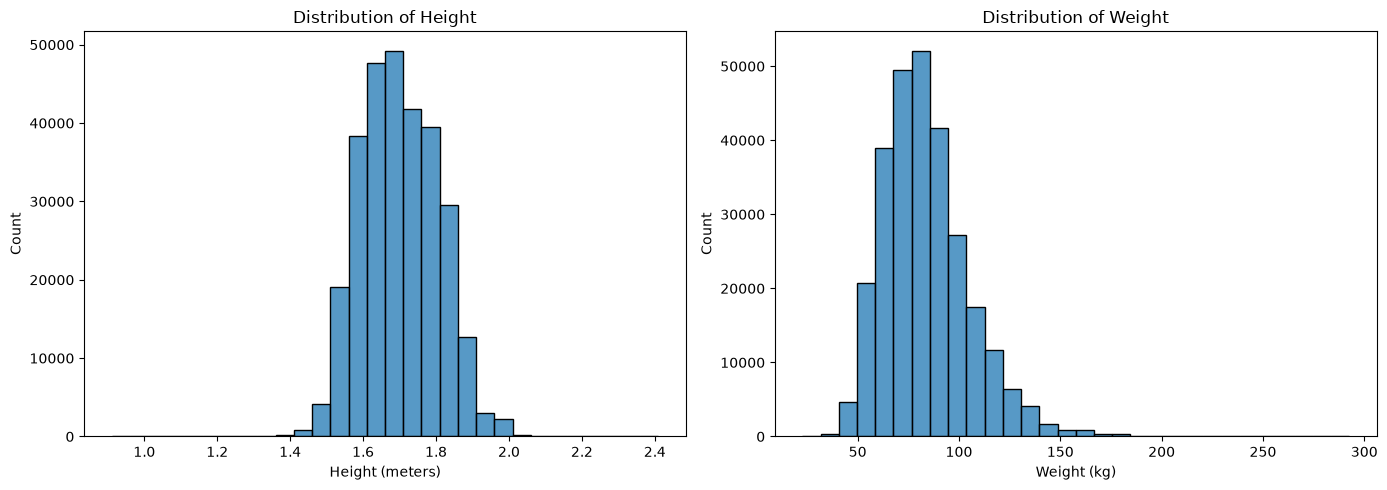

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["HeightInMeters"].dropna(), bins=30, ax=axes[0])
axes[0].set_title("Distribution of Height")
axes[0].set_xlabel("Height (meters)")
axes[0].set_ylabel("Count")

sns.histplot(df["WeightInKilograms"].dropna(), bins=30, ax=axes[1])
axes[1].set_title("Distribution of Weight")
axes[1].set_xlabel("Weight (kg)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

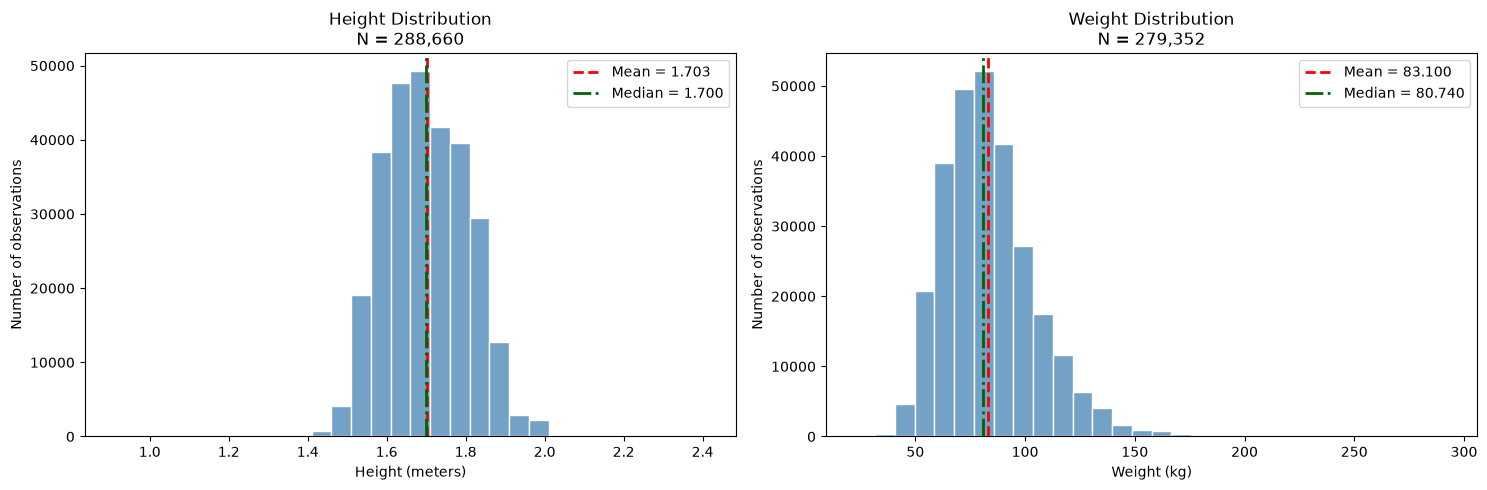

In [90]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

variables = [
    ("HeightInMeters", "Height Distribution", "Height (meters)"),
    ("WeightInKilograms", "Weight Distribution", "Weight (kg)")
]

for ax, (col, title, xlabel) in zip(axes, variables):

    values = df[col].dropna()

    mean_value = values.mean()
    median_value = values.median()

    sns.histplot(
        values,
        bins=30,
        ax=ax,
        color="steelblue",
        edgecolor="white"
    )

    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        linewidth=2,
       label=f"Mean = {mean_value:.3f}"
    )

    ax.axvline(
        median_value,
        color="darkgreen",
        linestyle="-.",
        linewidth=2,
        label=f"Median = {median_value:.3f}"
    )

    ax.set_title(f"{title}\nN = {len(values):,}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of observations")
    ax.legend()

plt.tight_layout()
plt.show()


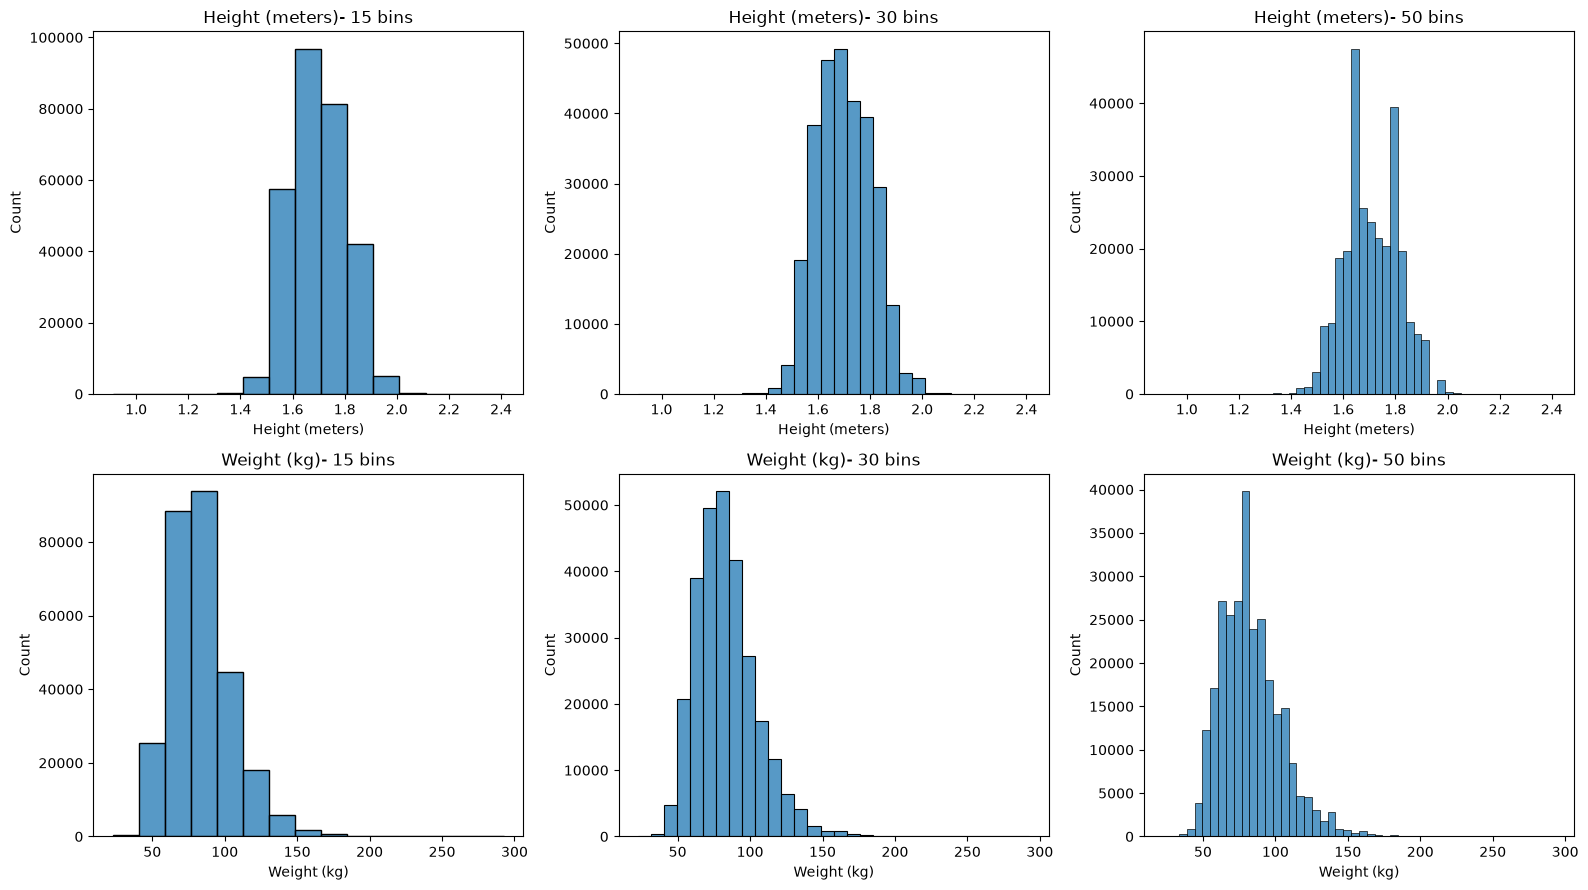

In [91]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

variables = [
    ("HeightInMeters", "Height (meters)"),
    ("WeightInKilograms", "Weight (kg)")
]

bin_choices = [15, 30, 50]

for row, (col, xlabel) in enumerate(variables):
    for column, bins in enumerate(bin_choices):

        sns.histplot(
            df[col].dropna(),
            bins=bins,
            ax=axes[row, column]
        )

        axes[row, column].set_title(
            f"{xlabel}- {bins} bins"
        )
        axes[row, column].set_xlabel(xlabel)
        axes[row, column].set_ylabel("Count")

plt.tight_layout()
plt.show()

In [92]:
numeric_features = [
    "HeightInMeters",
    "WeightInKilograms"
]

for col in numeric_features:

    print("\n" + "=" * 60)
    print(f"Comparison of {col} by Heart Disease")
    print("=" * 60)

    summary = (
        df.groupby("heart_disease")[col]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Std="std",
            Min="min",
            Q1=lambda x: x.quantile(0.25),
            Q3=lambda x: x.quantile(0.75),
            Max="max"
        )
    )

    print(summary.round(2))


Comparison of HeightInMeters by Heart Disease
                Count  Mean  Median   Std   Min    Q1    Q3   Max
heart_disease                                                    
0              262205  1.70     1.7  0.11  0.91  1.63  1.78  2.41
1               26455  1.71     1.7  0.11  0.91  1.63  1.78  2.41

Comparison of WeightInKilograms by Heart Disease
                Count   Mean  Median    Std    Min     Q1     Q3     Max
heart_disease                                                           
0              253539  82.77   79.83  21.37  22.68  68.04  94.35  292.57
1               25813  86.32   83.91  22.10  25.40  71.67  98.88  280.32


**Height and Weight by Heart Disease Status**

Height distributions were very similar between participants with and without heart disease. The mean height was 1.71 m in the heart disease group and 1.70 m in the non-heart disease group.

Weight showed a clearer difference. Participants with heart disease had a higher mean weight (86.32 kg) than those without heart disease (82.77 kg). Their median weight was also higher (83.91 kg vs. 79.83 kg).

These findings suggest that weight may contain useful predictive information, while height shows little difference between the two outcome groups. However, weight overlaps strongly with BMI, so its additional contribution should be evaluated carefully by Member 3.

In [93]:
# Compare height and weight distributions by heart disease outcome.
height_weight_by_outcome = (
    df.groupby("heart_disease")[["HeightInMeters", "WeightInKilograms"]]
      .agg(["count", "mean", "median", "std"])
)
print("Height and weight by heart disease outcome:")
print(height_weight_by_outcome.round(2).to_string())

Height and weight by heart disease outcome:
              HeightInMeters                    WeightInKilograms                     
                       count  mean median   std             count   mean median    std
heart_disease                                                                         
0                     262205  1.70    1.7  0.11            253539  82.77  79.83  21.37
1                      26455  1.71    1.7  0.11             25813  86.32  83.91  22.10


**Interpretation:** Height distributions were very similar between participants with and without heart disease. Weight showed a clearer difference: mean weight was approximately **86.32 kg** in the heart-disease group and **82.77 kg** in the no-heart-disease group. Since BMI, height and weight are related, check their redundancy before using them together in a model.

### Histogram bin selection

**Histogram Bin Selection:**

Histograms were compared using 15, 30, and 50 bins to assess how bin selection affects the interpretation of the distributions.

- 15 bins provided a simplified view but concealed some distribution details.
- 50 bins revealed more granular variation and made the plots visually busier.
- 30 bins provided a balanced representation of both height and weight distributions.

Therefore, 30 bins were selected for the final height and weight histograms.

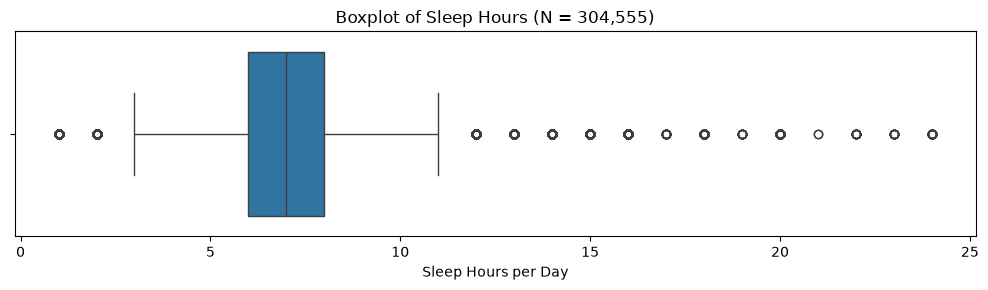

In [94]:
sleep_values = df["SleepHours"].dropna()

plt.figure(figsize=(10, 3))

sns.boxplot(x=sleep_values)

plt.title(f"Boxplot of Sleep Hours (N = {len(sleep_values):,})")
plt.xlabel("Sleep Hours per Day")

plt.tight_layout()
plt.show()

**Observations:**

- The median sleep duration is 7 hours, with the middle 50% of observations ranging from 6 to 8 hours.
- Potential outliers are observed below 3 hours and above 11 hours.
- These values were retained because IQR-based outliers do not necessarily indicate data errors.
- The analysis included 304,555 non-missing observations.

**Interpretation:** Comparing 15, 30 and 50 bins illustrates how histogram detail changes with bin width. The selected bin count should make the distribution readable without hiding important patterns or over-emphasizing noise.

### Outlier and measurement-consistency checks

In [95]:
import pandas as pd

checks = {
    "BMI > 50": ("BMI", lambda x: x > 50),
    "SleepHours < 4 or > 12": (
        "SleepHours", lambda x: (x < 4) | (x > 12)
    ),
    "PhysicalHealthDays = 30": (
        "PhysicalHealthDays", lambda x: x == 30
    ),
    "MentalHealthDays = 30": (
        "MentalHealthDays", lambda x: x == 30
    ),
    "Height < 1.3 or > 2.1": (
        "HeightInMeters", lambda x: (x < 1.3) | (x > 2.1)
    ),
    "Weight > 180": (
        "WeightInKilograms", lambda x: x > 180
    )
}

results = []

for label, (column, condition) in checks.items():
    values = pd.to_numeric(df[column], errors="coerce").dropna()
    count = condition(values).sum()

    results.append({
        "Check": label,
        "Count": count,
        "Percentage": count / len(values) * 100
    })

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

                  Check  Count  Percentage
               BMI > 50   2510       0.914
 SleepHours < 4 or > 12   5138       1.687
PhysicalHealthDays = 30  22637       7.526
  MentalHealthDays = 30  18464       6.113
  Height < 1.3 or > 2.1    254       0.088
           Weight > 180    553       0.198


In [96]:
import pandas as pd

checks = {
    "BMI": lambda x: x > 50,
    "SleepHours": lambda x: (x < 4) | (x > 12),
    "HeightInMeters": lambda x: (x < 1.3) | (x > 2.1),
    "WeightInKilograms": lambda x: x > 180
}

for col, condition in checks.items():

    values = pd.to_numeric(df[col], errors="coerce")
    unusual = df.loc[condition(values), col]

    print("\n" + "=" * 60)
    print(f"Variable: {col}")
    print(f"Minimum: {values.min()}")
    print(f"Maximum: {values.max()}")
    print(f"Unusual values count: {len(unusual)}")

    print("\nPercentiles:")
    print(values.quantile([0.01, 0.05, 0.50, 0.95, 0.99]).to_string())

    print("\nExamples of unusual values:")
    print(unusual.value_counts().head(10).to_string())


Variable: BMI
Minimum: 12.06
Maximum: 99.34
Unusual values count: 2510

Percentiles:
0.01    17.7500
0.05    20.1200
0.50    27.4400
0.95    40.6900
0.99    49.5798

Examples of unusual values:
BMI
51.49    73
53.14    47
50.22    45
51.65    42
50.18    42
51.21    37
53.25    37
56.68    33
53.22    28
54.87    28

Variable: SleepHours
Minimum: 1.0
Maximum: 24.0
Unusual values count: 5138

Percentiles:
0.01     3.0
0.05     5.0
0.50     7.0
0.95     9.0
0.99    12.0

Examples of unusual values:
SleepHours
3.0     2227
2.0     1053
1.0      771
15.0     228
14.0     216
16.0     212
13.0     118
18.0     117
20.0     105
24.0      35

Variable: HeightInMeters
Minimum: 0.91
Maximum: 2.41
Unusual values count: 254

Percentiles:
0.01    1.50
0.05    1.52
0.50    1.70
0.95    1.88
0.99    1.93

Examples of unusual values:
HeightInMeters
1.22    47
2.13    23
0.91    20
1.24    16
1.05    15
2.11    14
1.27    13
1.04    12
2.26    10
2.18     8

Variable: WeightInKilograms
Minimum: 22.68

In [97]:
# Check consistency between reported BMI and BMI calculated from height and weight

check_df = df[
    ["BMI", "HeightInMeters", "WeightInKilograms"]
].copy()

check_df = check_df.apply(pd.to_numeric, errors="coerce")

check_df["Calculated_BMI"] = (
    check_df["WeightInKilograms"] /
    (check_df["HeightInMeters"] ** 2)
)

check_df["BMI_Difference"] = (
    check_df["BMI"] - check_df["Calculated_BMI"]
).abs()

print("BMI consistency summary:")
print(
    check_df["BMI_Difference"]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(3)
    .to_string()
)

print("\nLargest BMI differences:")
print(
    check_df.nlargest(15, "BMI_Difference")[
        ["BMI", "HeightInMeters", "WeightInKilograms",
         "Calculated_BMI", "BMI_Difference"]
    ].round(2).to_string(index=False)
)

BMI consistency summary:
count    274752.000
mean          0.085
std           0.056
min           0.000
50%           0.079
90%           0.160
95%           0.185
99%           0.240
max           0.949

Largest BMI differences:
  BMI  HeightInMeters  WeightInKilograms  Calculated_BMI  BMI_Difference
97.65            0.91              81.65           98.60            0.95
92.22            0.91              77.11           93.12            0.90
89.51            0.91              74.84           90.38            0.87
82.77            0.97              77.11           81.95            0.82
81.37            0.91              68.04           82.16            0.79
80.83            0.91              67.59           81.62            0.79
78.88            0.97              73.48           78.10            0.78
77.03            0.91              64.41           77.78            0.75
73.24            0.91              61.23           73.94            0.70
67.81            0.91              56.7

**Interpretation:** The checks identify values that may warrant review, including very high BMI or weight, unusually short or long sleep duration, and extreme reported health-day counts. These are review flags, not automatic deletion criteria. The BMI consistency check compares reported BMI with BMI calculated from height and weight; discrepancies may arise from rounding, measurement differences or data-entry issues and should be investigated before deciding on treatment.

## 7. Relationships between features

This analysis examines correlations and selected relationships between numerical variables. Correlation describes association, not causation, and does not capture every nonlinear relationship.

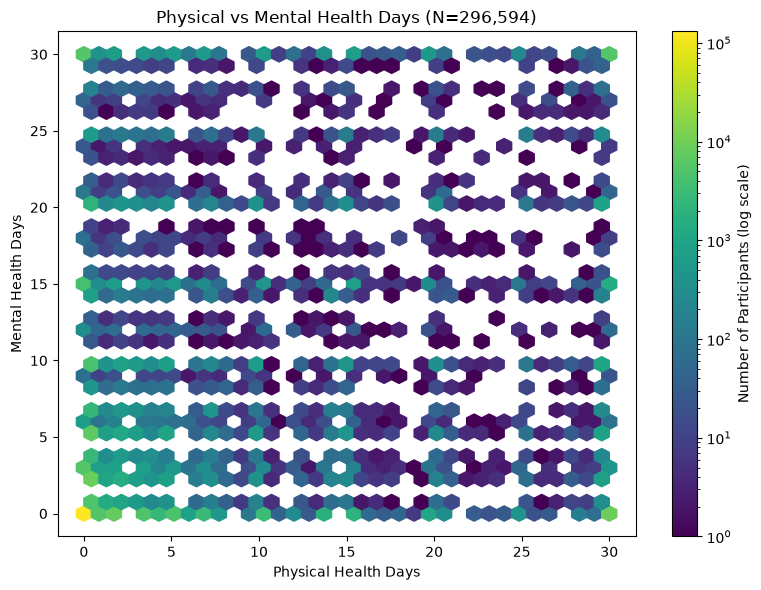

In [98]:
health_days = df[
    ["PhysicalHealthDays", "MentalHealthDays"]
].dropna()

plt.figure(figsize=(8, 6))

plt.hexbin(
    health_days["PhysicalHealthDays"],
    health_days["MentalHealthDays"],
    gridsize=35,
    bins="log",
    cmap="viridis"
)

plt.colorbar(label="Number of Participants (log scale)")
plt.title(
    f"Physical vs Mental Health Days (N={len(health_days):,})"
)
plt.xlabel("Physical Health Days")
plt.ylabel("Mental Health Days")
plt.tight_layout()
plt.show()

**Interpretation:**

The hexbin plot shows a positive but moderate relationship between PhysicalHealthDays and MentalHealthDays, consistent with the Spearman correlation of 0.31. Participants reporting more physically unhealthy days tend to report more mentally unhealthy days. However, the wide spread of observations suggests that the two variables provide different information. Both variables should be retained as candidate predictors until their contribution is evaluated during model validation.

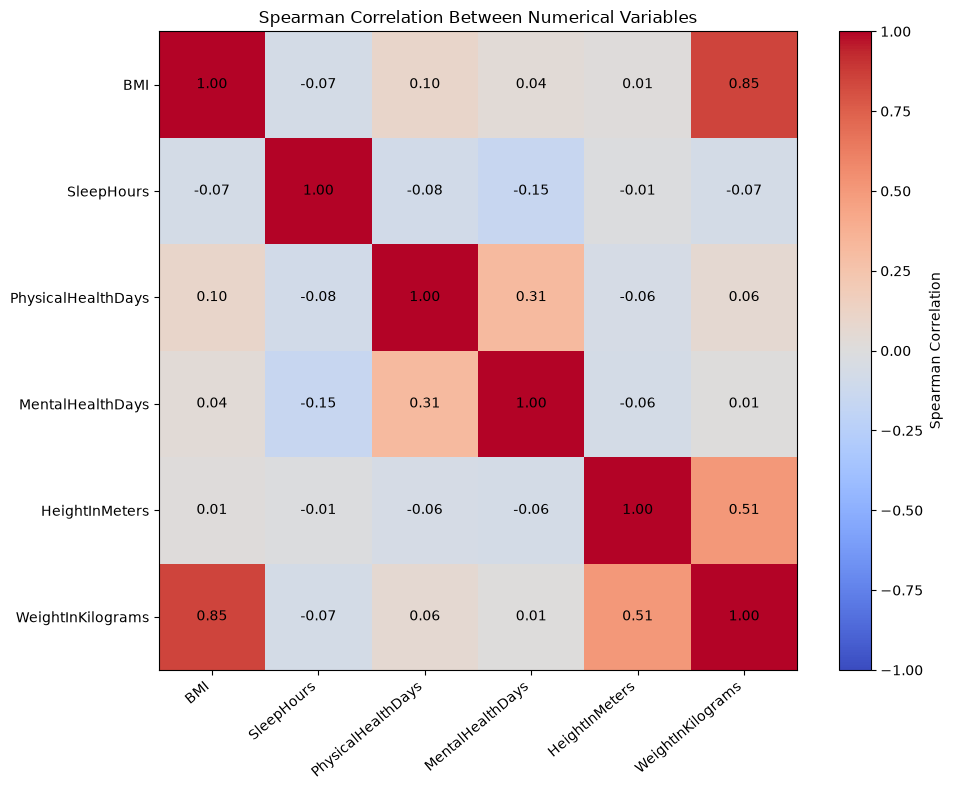

Saved: ..\results\figures\09_spearman_correlation_heatmap.png

Spearman Correlation Matrix:
                      BMI  SleepHours  PhysicalHealthDays  MentalHealthDays  HeightInMeters  WeightInKilograms
BMI                 1.000      -0.067               0.098             0.038           0.015              0.847
SleepHours         -0.067       1.000              -0.082            -0.150          -0.014             -0.065
PhysicalHealthDays  0.098      -0.082               1.000             0.313          -0.055              0.058
MentalHealthDays    0.038      -0.150               0.313             1.000          -0.064              0.005
HeightInMeters      0.015      -0.014              -0.055            -0.064           1.000              0.506
WeightInKilograms   0.847      -0.065               0.058             0.005           0.506              1.000


In [99]:
import matplotlib.pyplot as plt
import numpy as np

numeric_features = [
    "BMI",
    "SleepHours",
    "PhysicalHealthDays",
    "MentalHealthDays",
    "HeightInMeters",
    "WeightInKilograms"
]

correlation_matrix = df[numeric_features].corr(
    method="spearman"
)

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(numeric_features)))
ax.set_yticks(range(len(numeric_features)))

ax.set_xticklabels(numeric_features, rotation=40, ha="right")
ax.set_yticklabels(numeric_features)

for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):
        value = correlation_matrix.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=10
        )

colorbar = plt.colorbar(image, ax=ax)
colorbar.set_label("Spearman Correlation")

ax.set_title("Spearman Correlation Between Numerical Variables")

plt.tight_layout()

save_path = figures_folder / "09_spearman_correlation_heatmap.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved: {save_path}")
print("\nSpearman Correlation Matrix:")
print(correlation_matrix.round(3).to_string())

**Interpretation:** Physical health days and mental health days show a positive but moderate association (Spearman correlation approximately **0.31**). BMI and weight are strongly correlated (approximately **0.85**), while BMI and height have a very weak correlation (approximately **0.01**). This supports checking redundancy among anthropometric variables before modelling.

## 8. Additional categorical comparisons and data checks

The following analyses examine additional feature groups, including vaccination, functional difficulties, health behaviours and rare categories. These comparisons are exploratory and may be influenced by age and health status.

In [100]:
for col in ["RemovedTeeth", "HadStroke"]:
    print(f"\nHeart Disease by {col}")

    summary = df.groupby(
        col,
        dropna=False,
        observed=True
    )["heart_disease"].agg(["count", "mean"])

    summary["heart_disease_percent"] = summary["mean"] * 100

    display(summary.round(2))


Heart Disease by RemovedTeeth


,count,mean,heart_disease_percent
RemovedTeeth,,,
1 to 5,89358,0.10,10.02
"6 or more, but not all",31325,0.19,18.80
All,17452,0.24,24.28
None of them,162346,0.05,4.73
NaN,7599,0.14,14.08



Heart Disease by HadStroke


,count,mean,heart_disease_percent
HadStroke,,,
No,294284,0.08,7.77
Yes,13099,0.36,36.21
NaN,697,0.29,29.27


### Interpretation: Removed Teeth and Stroke

Participants who reported losing all their teeth had a higher heart disease percentage (24.28%) compared with those who had lost no teeth (4.73%). Heart disease percentage also increased across the tooth-loss categories.

Participants with a history of stroke had a substantially higher heart disease percentage (36.21%) than those without a history of stroke (7.77%).

These findings suggest that RemovedTeeth and HadStroke may be informative candidate predictors. However, these associations may be influenced by other factors, such as age, and do not establish causation.

In [101]:
for col in [
    "HadKidneyDisease",
    "HadCOPD",
    "HadArthritis",
    "HadAsthma",
    "HadDepressiveDisorder"
]:
    print(f"\nHeart Disease by {col}")

    summary = df.groupby(
        col,
        dropna=False,
        observed=True
    )["heart_disease"].agg(["count", "mean"])

    summary["heart_disease_percent"] = summary["mean"] * 100

    display(summary.round(2))


Heart Disease by HadKidneyDisease


,count,mean,heart_disease_percent
HadKidneyDisease,,,
No,293046,0.08,8.02
Yes,13956,0.29,29.31
NaN,1078,0.23,23.01



Heart Disease by HadCOPD


,count,mean,heart_disease_percent
HadCOPD,,,
No,282471,0.07,7.48
Yes,24413,0.26,26.47
NaN,1196,0.19,18.73



Heart Disease by HadArthritis


,count,mean,heart_disease_percent
HadArthritis,,,
No,202009,0.05,5.50
Yes,104530,0.16,15.86
NaN,1541,0.09,9.47



Heart Disease by HadAsthma


,count,mean,heart_disease_percent
HadAsthma,,,
No,260793,0.09,8.55
Yes,46303,0.12,11.67
NaN,984,0.12,12.20



Heart Disease by HadDepressiveDisorder


,count,mean,heart_disease_percent
HadDepressiveDisorder,,,
No,243353,0.08,8.44
Yes,63079,0.11,11.26
NaN,1648,0.12,11.53


### Interpretation: Other Health Conditions

Participants with kidney disease had a higher heart disease percentage (29.31%) than those without kidney disease (8.02%). A similar pattern was observed for COPD (26.47% vs. 7.48%) and arthritis (15.86% vs. 5.50%).

Asthma and depressive disorder showed smaller differences in heart disease percentages.

These findings suggest that kidney disease, COPD, and arthritis may be informative candidate predictors. Their contribution should be evaluated during model validation. These are observed associations and do not establish causation.

In [102]:
for col in [
    "FluVaxLast12",
    "PneumoVaxEver",
    "TetanusLast10Tdap"
]:
    print(f"\nHeart Disease by {col}")

    summary = df.groupby(
        col,
        dropna=False,
        observed=True
    )["heart_disease"].agg(["count", "mean"])

    summary["heart_disease_percent"] = summary["mean"] * 100

    display(summary.round(2))


Heart Disease by FluVaxLast12


,count,mean,heart_disease_percent
FluVaxLast12,,,
No,130574,0.07,6.76
Yes,145179,0.11,11.25
NaN,32327,0.08,8.27



Heart Disease by PneumoVaxEver


,count,mean,heart_disease_percent
PneumoVaxEver,,,
No,149466,0.05,5.34
Yes,105613,0.15,15.34
NaN,53001,0.07,6.88



Heart Disease by TetanusLast10Tdap


,count,mean,heart_disease_percent
TetanusLast10Tdap,,,
"No, did not receive any tetanus shot in the past 10 years",84159,0.10,9.73
"Yes, received Tdap",69568,0.07,7.04
"Yes, received tetanus shot but not sure what type",78591,0.10,10.02
"Yes, received tetanus shot, but not Tdap",19081,0.11,10.54
NaN,56681,0.09,8.56


### Interpretation: Vaccination Variables

Heart disease percentages differed across vaccination groups.

Participants who reported receiving a flu vaccine had a higher heart disease percentage (11.25%) than those who did not (6.76%). A similar difference was observed for pneumococcal vaccination (15.34% vs. 5.34%).

For tetanus vaccination, participants who reported receiving Tdap had a heart disease percentage of 7.04%, compared with 9.73% among those reporting no tetanus vaccination in the past 10 years.

These are descriptive associations, not evidence that vaccination increases or decreases heart disease. Age, existing health conditions, and healthcare use may influence these patterns. Vaccination variables should be retained as candidate predictors and evaluated during model validation.

In [103]:
excluded_cols = [
    "heart_disease",
    "row_id",
    "duplicate_group",
    "HadHeartAttack",
    "HadAngina"
]

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols
]

feature_inventory = pd.DataFrame({
    "Feature": feature_cols,
    "Data_Type": [df[col].dtype for col in feature_cols],
    "Unique_Values": [df[col].nunique(dropna=True) for col in feature_cols],
    "Missing_Count": [df[col].isna().sum() for col in feature_cols],
    "Missing_Percent": [df[col].isna().mean() * 100 for col in feature_cols]
})

display(feature_inventory)

,Feature,Data_Type,Unique_Values,Missing_Count,Missing_Percent
0,State,str,54,0,0.000000
1,Sex,str,2,0,0.000000
2,GeneralHealth,str,5,745,0.241820
3,PhysicalHealthDays,float64,31,7278,2.362373
4,MentalHealthDays,float64,31,6042,1.961179
5,LastCheckupTime,str,4,5589,1.814139
6,PhysicalActivities,str,2,683,0.221696
7,SleepHours,float64,24,3525,1.144183
8,RemovedTeeth,str,4,7599,2.466567
9,HadStroke,str,2,697,0.226240


In [104]:
features_to_compare = [
    "DeafOrHardOfHearing",
    "BlindOrVisionDifficulty",
    "DifficultyConcentrating",
    "DifficultyWalking"
]

comparison_results = []

for col in features_to_compare:
    temp = df[[col, "heart_disease"]].copy()
    temp[col] = temp[col].fillna("Missing")

    summary = (
        temp.groupby(col)["heart_disease"]
        .agg(
            Total="count",
            Heart_Disease_Cases="sum",
            Heart_Disease_Rate="mean"
        )
        .reset_index()
        .rename(columns={col: "Category"})
    )

    summary["Heart_Disease_Rate"] *= 100
    summary.insert(0, "Feature", col)

    comparison_results.append(summary)

feature_comparison = pd.concat(
    comparison_results,
    ignore_index=True
)

display(feature_comparison.round(2))

,Feature,Category,Total,Heart_Disease_Cases,Heart_Disease_Rate
0,DeafOrHardOfHearing,Missing,14013,1143,8.16
1,DeafOrHardOfHearing,No,267389,20997,7.85
2,DeafOrHardOfHearing,Yes,26678,5686,21.31
3,BlindOrVisionDifficulty,Missing,14661,1162,7.93
4,BlindOrVisionDifficulty,No,277253,23428,8.45
5,BlindOrVisionDifficulty,Yes,16166,3236,20.02
6,DifficultyConcentrating,Missing,16469,1325,8.05
7,DifficultyConcentrating,No,257224,21622,8.41
8,DifficultyConcentrating,Yes,34387,4879,14.19
9,DifficultyWalking,Missing,16306,1311,8.04


**Functional Difficulties and Heart Disease**

The comparison showed higher heart disease rates among participants reporting functional difficulties. The strongest differences were observed for difficulty walking (22.85% vs. 6.47%), deafness or hearing difficulty (21.31% vs. 7.85%), and blindness or vision difficulty (20.02% vs. 8.45%). Difficulty concentrating also showed a higher rate (14.19% vs. 8.41%).

These variables may provide useful information for the predictive model. However, the observed associations may partly reflect differences in age or general health and should not be interpreted as causal relationships. Member 3 can evaluate their contribution during model development.

In [105]:
features_to_compare = [
    "DifficultyDressingBathing",
    "DifficultyErrands",
    "HadSkinCancer"
]

comparison_results = []

for col in features_to_compare:
    temp = df[[col, "heart_disease"]].copy()
    temp[col] = temp[col].fillna("Missing")

    summary = (
        temp.groupby(col)["heart_disease"]
        .agg(
            Total="count",
            Heart_Disease_Cases="sum",
            Heart_Disease_Rate="mean"
        )
        .reset_index()
        .rename(columns={col: "Category"})
    )

    summary["Heart_Disease_Rate"] *= 100
    summary.insert(0, "Feature", col)
    comparison_results.append(summary)

feature_comparison = pd.concat(comparison_results, ignore_index=True)

print(feature_comparison.round(2).to_string(index=False))

                  Feature Category  Total  Heart_Disease_Cases  Heart_Disease_Rate
DifficultyDressingBathing  Missing  16228                 1255                7.73
DifficultyDressingBathing       No 280370                23720                8.46
DifficultyDressingBathing      Yes  11482                 2851               24.83
        DifficultyErrands  Missing  17470                 1388                7.95
        DifficultyErrands       No 268475                21834                8.13
        DifficultyErrands      Yes  22135                 4604               20.80
            HadSkinCancer  Missing   1870                  333               17.81
            HadSkinCancer       No 281626                23313                8.28
            HadSkinCancer      Yes  24584                 4180               17.00


In [106]:
features_to_compare = [
    "ECigaretteUsage",
    "ChestScan",
    "AlcoholDrinkers"
]

comparison_results = []

for col in features_to_compare:

    temp = df[[col, "heart_disease"]].copy()

    temp[col] = temp[col].fillna("Missing")

    summary = (
        temp.groupby(col)["heart_disease"]
        .agg(
            Total="count",
            Heart_Disease_Cases="sum",
            Heart_Disease_Rate="mean"
        )
        .reset_index()
        .rename(columns={col: "Category"})
    )

    summary["Heart_Disease_Rate"] *= 100
    summary.insert(0, "Feature", col)

    comparison_results.append(summary)

feature_comparison = pd.concat(
    comparison_results,
    ignore_index=True
)

print(feature_comparison.round(2).to_string(index=False))

        Feature                                  Category  Total  Heart_Disease_Cases  Heart_Disease_Rate
ECigaretteUsage                                   Missing  24458                 2067                8.45
ECigaretteUsage Never used e-cigarettes in my entire life 216387                20435                9.44
ECigaretteUsage                    Not at all (right now)  51957                 4517                8.69
ECigaretteUsage                        Use them every day   7177                  346                4.82
ECigaretteUsage                        Use them some days   8101                  461                5.69
      ChestScan                                   Missing  38383                 3429                8.93
      ChestScan                                        No 155157                 5529                3.56
      ChestScan                                       Yes 114540                18868               16.47
AlcoholDrinkers                               

In [107]:
features_to_compare = [
    "HIVTesting",
    "HighRiskLastYear",
    "CovidPos"
]

comparison_results = []

for col in features_to_compare:

    temp = df[[col, "heart_disease"]].copy()
    temp[col] = temp[col].fillna("Missing")

    summary = (
        temp.groupby(col)["heart_disease"]
        .agg(
            Total="count",
            Heart_Disease_Cases="sum",
            Heart_Disease_Rate="mean"
        )
        .reset_index()
        .rename(columns={col: "Category"})
    )

    summary["Heart_Disease_Rate"] *= 100
    summary.insert(0, "Feature", col)

    comparison_results.append(summary)

feature_comparison = pd.concat(
    comparison_results,
    ignore_index=True
)

print(feature_comparison.round(2).to_string(index=False))

         Feature                                                      Category  Total  Heart_Disease_Cases  Heart_Disease_Rate
      HIVTesting                                                       Missing  45404                 4196                9.24
      HIVTesting                                                            No 173182                16549                9.56
      HIVTesting                                                           Yes  89494                 7081                7.91
HighRiskLastYear                                                       Missing  34754                 2906                8.36
HighRiskLastYear                                                            No 261383                24325                9.31
HighRiskLastYear                                                           Yes  11943                  595                4.98
        CovidPos                                                       Missing  34810                 2865     

In [108]:
features_to_compare = [
    "LastCheckupTime",
    "RaceEthnicityCategory"
]

comparison_results = []

for col in features_to_compare:

    temp = df[[col, "heart_disease"]].copy()
    temp[col] = temp[col].fillna("Missing")

    summary = (
        temp.groupby(col)["heart_disease"]
        .agg(
            Total="count",
            Heart_Disease_Cases="sum",
            Heart_Disease_Rate="mean"
        )
        .reset_index()
        .rename(columns={col: "Category"})
    )

    summary["Heart_Disease_Rate"] *= 100
    summary.insert(0, "Feature", col)

    comparison_results.append(summary)

feature_comparison = pd.concat(
    comparison_results,
    ignore_index=True
)

print(feature_comparison.round(2).to_string(index=False))

              Feature                                                Category  Total  Heart_Disease_Cases  Heart_Disease_Rate
      LastCheckupTime                                     5 or more years ago  13200                  395                2.99
      LastCheckupTime                                                 Missing   5589                  328                5.87
      LastCheckupTime  Within past 2 years (1 year but less than 2 years ago)  29029                 1256                4.33
      LastCheckupTime Within past 5 years (2 years but less than 5 years ago)  17230                  528                3.06
      LastCheckupTime      Within past year (anytime less than 12 months ago) 243032                25319               10.42
RaceEthnicityCategory                                Black only, Non-Hispanic  24434                 1886                7.72
RaceEthnicityCategory                                                Hispanic  29595                 1683             

In [109]:
state_summary = (
    df.groupby("State")["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Cases="sum",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

state_summary["Heart_Disease_Rate"] *= 100

state_summary = state_summary.sort_values(
    "Heart_Disease_Rate",
    ascending=False
)

print(state_summary.round(2).to_string(index=False))

               State  Total  Heart_Disease_Cases  Heart_Disease_Rate
            Arkansas   3621                  507               14.00
       West Virginia   3466                  478               13.79
             Alabama   3125                  402               12.86
             Florida   9313                 1137               12.21
            Kentucky   2720                  310               11.40
            Oklahoma   3883                  440               11.33
                Ohio  11355                 1260               11.10
               Maine   7358                  816               11.09
       New Hampshire   4667                  511               10.95
           Louisiana   3895                  417               10.71
            Nebraska   5174                  548               10.59
           Tennessee   3650                  384               10.52
             Indiana   7303                  759               10.39
        South Dakota   5167       

### Functional difficulties and additional features — interpretation

The comparisons indicate higher observed heart disease percentages among participants reporting functional difficulties. Examples include difficulty walking (**22.85%** vs. **6.47%**), difficulty dressing or bathing (**24.83%** vs. **8.46%**), and difficulty running errands (**20.80%** vs. **8.13%**).

These differences may reflect age and overall health burden. Rare categories and categories with small sample sizes should be treated cautiously; check group counts alongside percentages.

In [110]:
excluded_cols = [
    "heart_disease",
    "row_id",
    "duplicate_group",
    "HadHeartAttack",
    "HadAngina"
]

categorical_features = [
    col for col in df.select_dtypes(exclude="number").columns
    if col not in excluded_cols
]

for col in categorical_features:

    counts = df[col].value_counts(dropna=False)

    rare_categories = counts[counts < 30]

    if len(rare_categories) > 0:
        print(f"\n{col}")
        print(rare_categories)

In [111]:
for col in categorical_features:

    counts = df[col].value_counts(dropna=False)
    rare_categories = counts[counts < 1000]

    if len(rare_categories) > 0:
        print(f"\n{'=' * 50}")
        print(f"Feature: {col}")
        print(rare_categories.to_string())


Feature: GeneralHealth
GeneralHealth
NaN    745

Feature: PhysicalActivities
PhysicalActivities
NaN    683

Feature: HadStroke
HadStroke
NaN    697

Feature: HadAsthma
HadAsthma
NaN    984

Feature: HadDiabetes
HadDiabetes
NaN    524


In [112]:
for col in categorical_features:

    values = df[col].dropna().astype(str)

    # Check extra spaces
    extra_spaces = values[values != values.str.strip()]

    # Check different spellings that become identical after cleaning
    temp = pd.DataFrame({
        "Original": values,
        "Normalized": values.str.strip().str.lower()
    })

    spelling_variants = (
        temp.groupby("Normalized")["Original"]
        .nunique()
    )

    spelling_variants = spelling_variants[spelling_variants > 1]

    if len(extra_spaces) > 0 or len(spelling_variants) > 0:

        print(f"\n{'=' * 50}")
        print(f"Feature: {col}")

        if len(extra_spaces) > 0:
            print("\nValues with extra spaces:")
            print(extra_spaces.value_counts().to_string())

        if len(spelling_variants) > 0:
            print("\nDifferent spellings of the same category:")
            for category in spelling_variants.index:
                print(category)
                print(
                    temp[temp["Normalized"] == category]
                    ["Original"].value_counts().to_string()
                )

### Data consistency and rare-category checks — interpretation

The rare-category and text-format checks help identify categories with very small counts, inconsistent spacing or spelling variants. Such issues should be reviewed before encoding categorical features. Categories should not be merged solely because their counts are small; any grouping should be clinically or contextually justified and documented.

## 9. Stratified analysis by age and sex

Overall comparisons can be influenced by differences in age and sex composition. This analysis examines selected associations within age and sex groups to see whether broad patterns remain visible. Small subgroup counts can produce unstable percentages.

In [113]:
age_order = [
    "Age 18 to 24",
    "Age 25 to 29",
    "Age 30 to 34",
    "Age 35 to 39",
    "Age 40 to 44",
    "Age 45 to 49",
    "Age 50 to 54",
    "Age 55 to 59",
    "Age 60 to 64",
    "Age 65 to 69",
    "Age 70 to 74",
    "Age 75 to 79",
    "Age 80 or older"
]

,AgeCategory,Sex,count,mean,heart_disease_percent
0,Age 18 to 24,Female,8097,0.01,0.65
1,Age 18 to 24,Male,10571,0.01,0.87
2,Age 25 to 29,Female,7262,0.01,0.91
3,Age 25 to 29,Male,8068,0.01,1.07
4,Age 30 to 34,Female,9017,0.01,1.05
5,Age 30 to 34,Male,8912,0.01,1.41
6,Age 35 to 39,Female,10146,0.02,1.53
7,Age 35 to 39,Male,9739,0.02,1.76
8,Age 40 to 44,Female,10867,0.02,2.04
9,Age 40 to 44,Male,9908,0.03,2.69


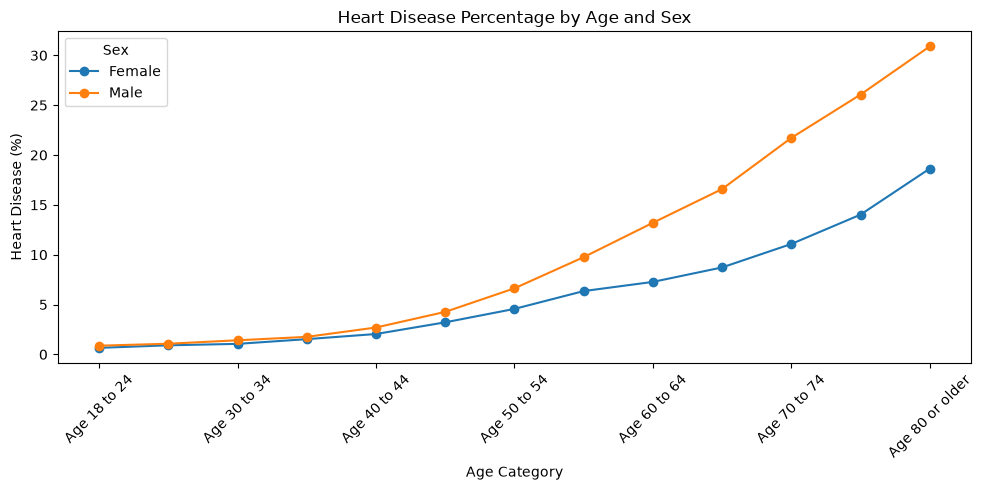

In [114]:
age_sex_summary = (
    df.dropna(subset=["AgeCategory", "Sex"])
    .groupby(["AgeCategory", "Sex"], observed=True)["heart_disease"]
    .agg(["count", "mean"])
    .reset_index()
)

age_sex_summary["heart_disease_percent"] = (
    age_sex_summary["mean"] * 100
)

display(age_sex_summary.round(2))

age_sex_rates = age_sex_summary.pivot(
    index="AgeCategory",
    columns="Sex",
    values="heart_disease_percent"
).reindex(age_order)

age_sex_rates.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Heart Disease Percentage by Age and Sex")
plt.xlabel("Age Category")
plt.ylabel("Heart Disease (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Age and sex — interpretation

Heart disease percentages increase with age in both sexes, and males generally show higher percentages than females within age categories. For example, in the 80+ group the observed rates were approximately **30.90%** for males and **18.64%** for females. These comparisons show why age and sex should be considered when interpreting overall feature differences.

In [115]:
activity_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "PhysicalActivities"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

activity_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    activity_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex PhysicalActivities  Total  Heart_Disease_Rate
   Age 18 to 24 Female                 No   1566                1.02
   Age 18 to 24 Female                Yes   6511                0.57
   Age 18 to 24   Male                 No   1483                1.08
   Age 18 to 24   Male                Yes   9072                0.84
   Age 25 to 29 Female                 No   1407                0.85
   Age 25 to 29 Female                Yes   5846                0.92
   Age 25 to 29   Male                 No   1153                1.73
   Age 25 to 29   Male                Yes   6898                0.96
   Age 30 to 34 Female                 No   1840                1.68
   Age 30 to 34 Female                Yes   7161                0.89
   Age 30 to 34   Male                 No   1353                2.00
   Age 30 to 34   Male                Yes   7542                1.31
   Age 35 to 39 Female                 No   2057                2.09
   Age 35 to 39 Female            

**Physical Activity by Age and Sex**

The comparison showed that the heart disease rate was generally higher among participants who reported no physical activity, across most age and sex groups. The difference was particularly noticeable in older age groups. Heart disease rates also increased with age in both sexes, while males generally showed higher rates than females.

This suggests that the observed association between physical activity and heart disease is not explained by age and sex differences alone. However, these are descriptive findings and do not establish a causal relationship.

In [116]:
smoking_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "SmokerStatus"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

smoking_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    smoking_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex                          SmokerStatus  Total  Heart_Disease_Rate
   Age 18 to 24 Female Current smoker - now smokes every day    202                2.97
   Age 18 to 24 Female Current smoker - now smokes some days    158                1.27
   Age 18 to 24 Female                         Former smoker    401                1.25
   Age 18 to 24 Female                          Never smoked   6678                0.54
   Age 18 to 24   Male Current smoker - now smokes every day    324                5.56
   Age 18 to 24   Male Current smoker - now smokes some days    438                1.83
   Age 18 to 24   Male                         Former smoker    754                1.06
   Age 18 to 24   Male                          Never smoked   8288                0.59
   Age 25 to 29 Female Current smoker - now smokes every day    369                1.36
   Age 25 to 29 Female Current smoker - now smokes some days    230                2.61
   Age 25 to 29 Female          

In [117]:
diabetes_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "HadDiabetes"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

diabetes_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    diabetes_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex                             HadDiabetes  Total  Heart_Disease_Rate
   Age 18 to 24 Female                                      No   7795                0.58
   Age 18 to 24 Female No, pre-diabetes or borderline diabetes     75                2.67
   Age 18 to 24 Female                                     Yes    106                2.83
   Age 18 to 24 Female Yes, but only during pregnancy (female)    109                2.75
   Age 18 to 24   Male                                      No  10323                0.77
   Age 18 to 24   Male No, pre-diabetes or borderline diabetes     69                1.45
   Age 18 to 24   Male                                     Yes    133                7.52
   Age 18 to 24   Male Yes, but only during pregnancy (female)      2                0.00
   Age 25 to 29 Female                                      No   6850                0.79
   Age 25 to 29 Female No, pre-diabetes or borderline diabetes     82                2.44
   Age 25 

In [118]:
health_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "GeneralHealth"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

health_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    health_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex GeneralHealth  Total  Heart_Disease_Rate
   Age 18 to 24 Female     Excellent   1553                0.32
   Age 18 to 24 Female          Fair    815                1.47
   Age 18 to 24 Female          Good   2610                0.57
   Age 18 to 24 Female          Poor    130                7.69
   Age 18 to 24 Female     Very good   2980                0.37
   Age 18 to 24   Male     Excellent   2660                0.71
   Age 18 to 24   Male          Fair    932                1.07
   Age 18 to 24   Male          Good   3102                0.93
   Age 18 to 24   Male          Poor    148                8.78
   Age 18 to 24   Male     Very good   3706                0.57
   Age 25 to 29 Female     Excellent   1453                0.55
   Age 25 to 29 Female          Fair    749                2.27
   Age 25 to 29 Female          Good   2259                0.89
   Age 25 to 29 Female          Poor    111                6.31
   Age 25 to 29 Female     Very good   2

In [119]:
bmi_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "BMI_Group"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

bmi_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    bmi_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex         BMI_Group  Total  Heart_Disease_Rate
   Age 18 to 24 Female       Underweight    334                0.90
   Age 18 to 24 Female            Normal   3406                0.56
   Age 18 to 24 Female        Overweight   1624                0.37
   Age 18 to 24 Female   Obesity Class I    843                0.36
   Age 18 to 24 Female  Obesity Class II    404                1.24
   Age 18 to 24 Female Obesity Class III    331                0.60
   Age 18 to 24   Male       Underweight    470                1.70
   Age 18 to 24   Male            Normal   4499                0.69
   Age 18 to 24   Male        Overweight   2664                0.75
   Age 18 to 24   Male   Obesity Class I   1192                1.17
   Age 18 to 24   Male  Obesity Class II    453                0.44
   Age 18 to 24   Male Obesity Class III    315                0.63
   Age 25 to 29 Female       Underweight    143                2.10
   Age 25 to 29 Female            Normal   2330 

In [120]:
stroke_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "HadStroke"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

stroke_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    stroke_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex HadStroke  Total  Heart_Disease_Rate
   Age 18 to 24 Female        No   8050                0.51
   Age 18 to 24 Female       Yes     37               32.43
   Age 18 to 24   Male        No  10517                0.72
   Age 18 to 24   Male       Yes     39               30.77
   Age 25 to 29 Female        No   7213                0.73
   Age 25 to 29 Female       Yes     44               27.27
   Age 25 to 29   Male        No   8020                0.94
   Age 25 to 29   Male       Yes     35               25.71
   Age 30 to 34 Female        No   8942                0.97
   Age 30 to 34 Female       Yes     70               11.43
   Age 30 to 34   Male        No   8832                1.19
   Age 30 to 34   Male       Yes     69               27.54
   Age 35 to 39 Female        No   9994                1.28
   Age 35 to 39 Female       Yes    135               17.78
   Age 35 to 39   Male        No   9638                1.49
   Age 35 to 39   Male       Yes     85 

In [121]:
kidney_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "HadKidneyDisease"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

kidney_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    kidney_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex HadKidneyDisease  Total  Heart_Disease_Rate
   Age 18 to 24 Female               No   8013                0.61
   Age 18 to 24 Female              Yes     68                5.88
   Age 18 to 24   Male               No  10492                0.81
   Age 18 to 24   Male              Yes     65                7.69
   Age 25 to 29 Female               No   7163                0.85
   Age 25 to 29 Female              Yes     86                4.65
   Age 25 to 29   Male               No   7998                0.99
   Age 25 to 29   Male              Yes     53                9.43
   Age 30 to 34 Female               No   8866                1.02
   Age 30 to 34 Female              Yes    139                3.60
   Age 30 to 34   Male               No   8802                1.34
   Age 30 to 34   Male              Yes     93                7.53
   Age 35 to 39 Female               No   9941                1.30
   Age 35 to 39 Female              Yes    187               1

In [122]:
copd_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "HadCOPD"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

copd_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    copd_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex HadCOPD  Total  Heart_Disease_Rate
   Age 18 to 24 Female      No   7919                0.58
   Age 18 to 24 Female     Yes    152                4.61
   Age 18 to 24   Male      No  10368                0.80
   Age 18 to 24   Male     Yes    153                5.88
   Age 25 to 29 Female      No   7066                0.83
   Age 25 to 29 Female     Yes    168                4.17
   Age 25 to 29   Male      No   7916                0.99
   Age 25 to 29   Male     Yes    122                5.74
   Age 30 to 34 Female      No   8764                0.89
   Age 30 to 34 Female     Yes    235                7.23
   Age 30 to 34   Male      No   8706                1.22
   Age 30 to 34   Male     Yes    167               11.38
   Age 35 to 39 Female      No   9790                1.28
   Age 35 to 39 Female     Yes    338                7.99
   Age 35 to 39   Male      No   9497                1.54
   Age 35 to 39   Male     Yes    214               11.21
   Age 40 to 4

In [123]:
arthritis_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "HadArthritis"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

arthritis_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    arthritis_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex HadArthritis  Total  Heart_Disease_Rate
   Age 18 to 24 Female           No   7698                0.47
   Age 18 to 24 Female          Yes    368                4.35
   Age 18 to 24   Male           No  10251                0.78
   Age 18 to 24   Male          Yes    269                4.09
   Age 25 to 29 Female           No   6709                0.70
   Age 25 to 29 Female          Yes    513                3.51
   Age 25 to 29   Male           No   7709                0.88
   Age 25 to 29   Male          Yes    328                5.49
   Age 30 to 34 Female           No   8110                0.84
   Age 30 to 34 Female          Yes    865                3.12
   Age 30 to 34   Male           No   8219                1.18
   Age 30 to 34   Male          Yes    653                4.44
   Age 35 to 39 Female           No   8670                1.00
   Age 35 to 39 Female          Yes   1427                4.48
   Age 35 to 39   Male           No   8679             

In [124]:
asthma_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "HadAsthma"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

asthma_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    asthma_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex HadAsthma  Total  Heart_Disease_Rate
   Age 18 to 24 Female        No   6477                0.52
   Age 18 to 24 Female       Yes   1575                1.21
   Age 18 to 24   Male        No   8609                0.73
   Age 18 to 24   Male       Yes   1891                1.53
   Age 25 to 29 Female        No   5755                0.66
   Age 25 to 29 Female       Yes   1480                1.89
   Age 25 to 29   Male        No   6707                0.85
   Age 25 to 29   Male       Yes   1331                2.03
   Age 30 to 34 Female        No   7193                0.76
   Age 30 to 34 Female       Yes   1795                2.17
   Age 30 to 34   Male        No   7577                1.07
   Age 30 to 34   Male       Yes   1298                3.39
   Age 35 to 39 Female        No   8275                1.15
   Age 35 to 39 Female       Yes   1853                3.24
   Age 35 to 39   Male        No   8358                1.50
   Age 35 to 39   Male       Yes   1349 

In [125]:
depression_by_age_sex = (
    df.groupby(
        ["AgeCategory", "Sex", "HadDepressiveDisorder"],
        observed=True
    )["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

depression_by_age_sex["Heart_Disease_Rate"] *= 100

print(
    depression_by_age_sex
    .round(2)
    .to_string(index=False)
)

    AgeCategory    Sex HadDepressiveDisorder  Total  Heart_Disease_Rate
   Age 18 to 24 Female                    No   5083                0.47
   Age 18 to 24 Female                   Yes   2931                0.96
   Age 18 to 24   Male                    No   8451                0.65
   Age 18 to 24   Male                   Yes   1977                1.72
   Age 25 to 29 Female                    No   4695                0.64
   Age 25 to 29 Female                   Yes   2511                1.39
   Age 25 to 29   Male                    No   6499                0.89
   Age 25 to 29   Male                   Yes   1516                1.85
   Age 30 to 34 Female                    No   5995                0.70
   Age 30 to 34 Female                   Yes   2958                1.72
   Age 30 to 34   Male                    No   7141                0.91
   Age 30 to 34   Male                   Yes   1714                3.56
   Age 35 to 39 Female                    No   6955             

### Stratified feature comparisons — interpretation

The stratified tables provide a more detailed view of physical activity, smoking, diabetes, general health, BMI and selected health conditions across age and sex groups. They help assess whether an overall association is also visible within demographic strata.

These tables are descriptive and may contain small subgroups. They should support interpretation, not replace multivariable modelling or validation.

## 10. Figures and reproducible outputs

The following cells define and generate consistent rate plots, including explicit missing categories where appropriate. The function definition is placed before its calls so the notebook can be run sequentially.

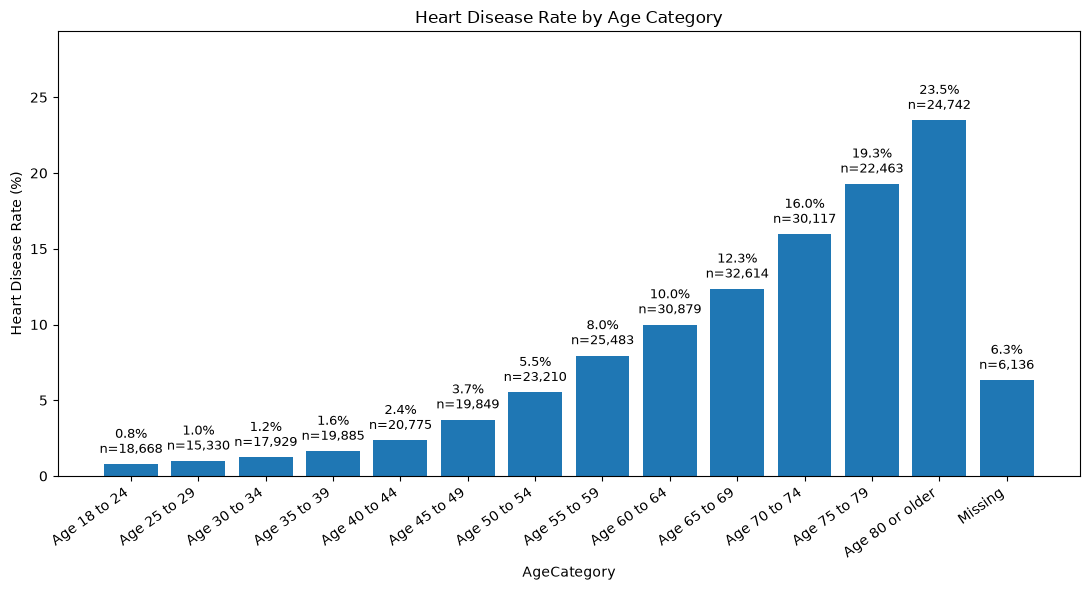


Saved: ..\results\figures\01_heart_disease_by_age.png
    AgeCategory  Total      Rate
   Age 18 to 24  18668  0.776730
   Age 25 to 29  15330  0.991520
   Age 30 to 34  17929  1.232640
   Age 35 to 39  19885  1.639427
   Age 40 to 44  20775  2.353791
   Age 45 to 49  19849  3.713033
   Age 50 to 54  23210  5.523481
   Age 55 to 59  25483  7.950398
   Age 60 to 64  30879  9.990609
   Age 65 to 69  32614 12.347458
   Age 70 to 74  30117 15.961085
   Age 75 to 79  22463 19.280595
Age 80 or older  24742 23.482338
        Missing   6136  6.323338


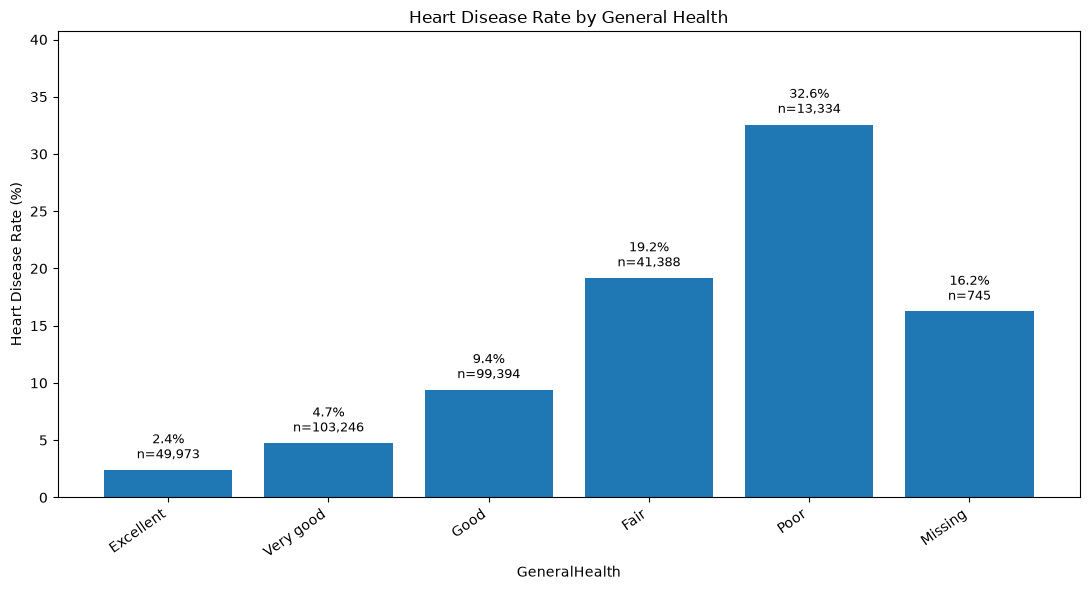


Saved: ..\results\figures\02_heart_disease_by_general_health.png
GeneralHealth  Total      Rate
    Excellent  49973  2.395293
    Very good 103246  4.737230
         Good  99394  9.398958
         Fair  41388 19.164975
         Poor  13334 32.570871
      Missing    745 16.241611


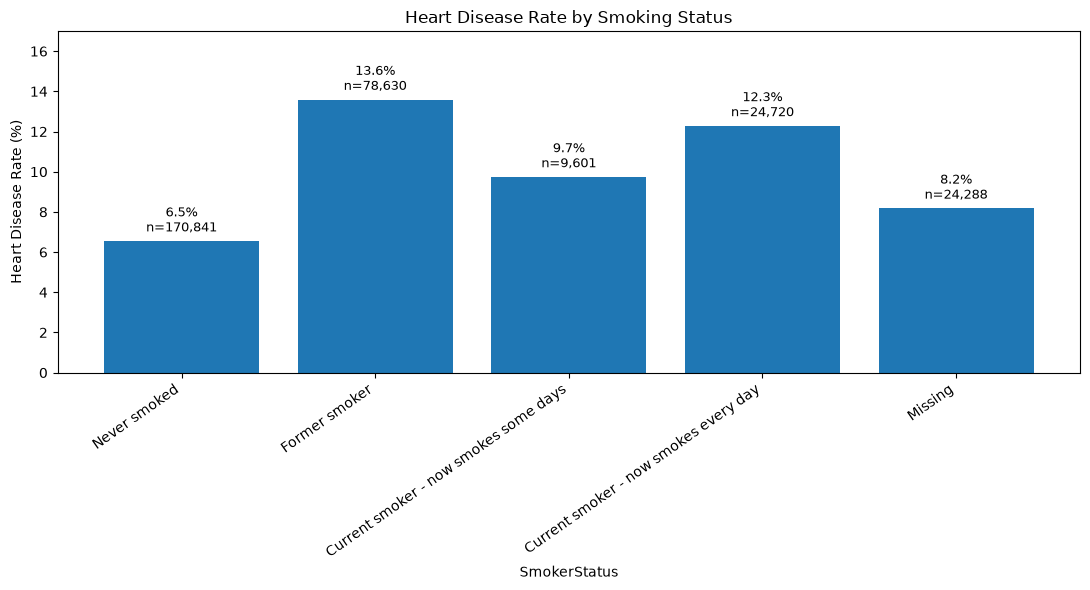


Saved: ..\results\figures\03_heart_disease_by_smoking.png
                         SmokerStatus  Total      Rate
                         Never smoked 170841  6.545853
                        Former smoker  78630 13.590233
Current smoker - now smokes some days   9601  9.738569
Current smoker - now smokes every day  24720 12.281553
                              Missing  24288  8.176877


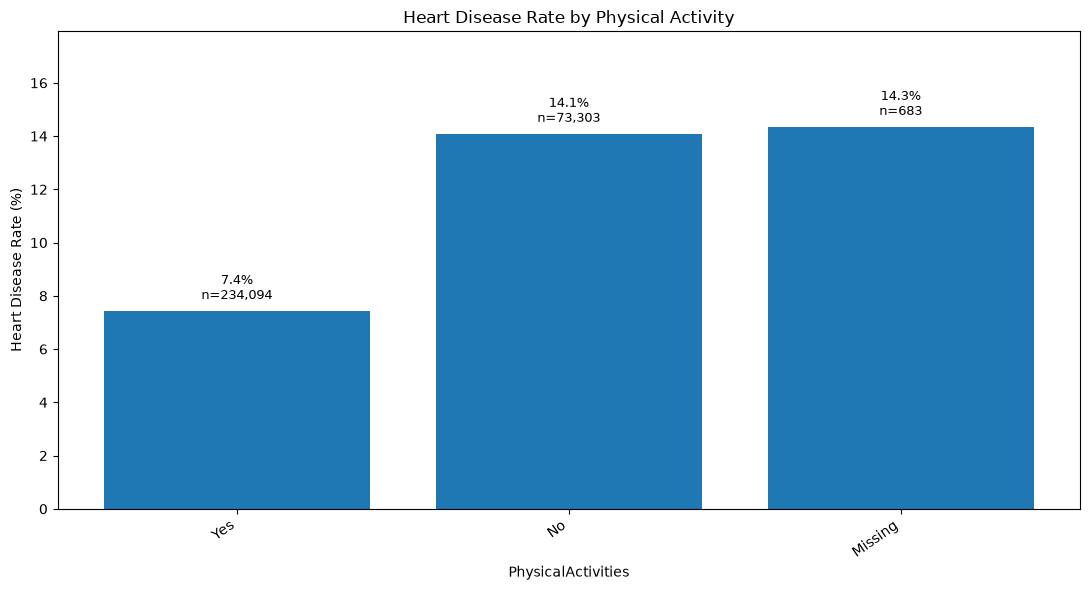


Saved: ..\results\figures\04_heart_disease_by_physical_activity.png
PhysicalActivities  Total      Rate
               Yes 234094  7.433339
                No  73303 14.088100
           Missing    683 14.348463


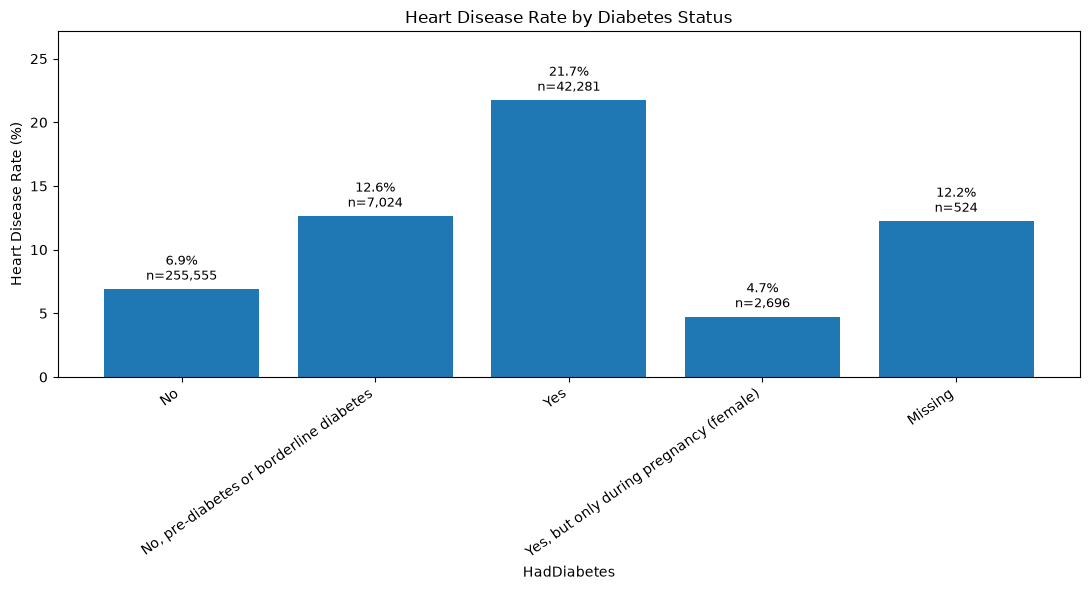


Saved: ..\results\figures\05_heart_disease_by_diabetes.png
                            HadDiabetes  Total      Rate
                                     No 255555  6.873667
No, pre-diabetes or borderline diabetes   7024 12.613895
                                    Yes  42281 21.718975
Yes, but only during pregnancy (female)   2696  4.710682
                                Missing    524 12.213740


In [126]:
def save_rate_plot(column, title, filename, order=None):

    temp = df[[column, "heart_disease"]].copy()
    temp[column] = temp[column].astype("object").fillna("Missing").astype(str)

    rates = (
        temp.groupby(column)["heart_disease"]
        .agg(Total="count", Rate="mean")
        .reset_index()
    )

    rates["Rate"] *= 100

    if order is not None:
        order = [str(x) for x in order]
        remaining = [x for x in rates[column] if x not in order]
        final_order = order + remaining

        rates[column] = pd.Categorical(
            rates[column],
            categories=final_order,
            ordered=True
        )
        rates = rates.sort_values(column)

    rates = rates.reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(11, 6))

    positions = range(len(rates))
    bars = ax.bar(positions, rates["Rate"])

    ax.set_xticks(list(positions))
    ax.set_xticklabels(
        rates[column].astype(str).tolist(),
        rotation=35,
        ha="right"
    )

    ax.set_title(title)
    ax.set_xlabel(column)
    ax.set_ylabel("Heart Disease Rate (%)")
    ax.set_ylim(0, rates["Rate"].max() * 1.25)

    for bar, rate, total in zip(
        bars, rates["Rate"], rates["Total"]
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + rates["Rate"].max() * 0.02,
            f"{rate:.1f}%\nn={total:,}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    plt.tight_layout()

    path = figures_folder / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"\nSaved: {path}")
    print(rates.to_string(index=False))


save_rate_plot(
    "AgeCategory",
    "Heart Disease Rate by Age Category",
    "01_heart_disease_by_age.png",
    age_order
)

save_rate_plot(
    "GeneralHealth",
    "Heart Disease Rate by General Health",
    "02_heart_disease_by_general_health.png",
    ["Excellent", "Very good", "Good", "Fair", "Poor", "Missing"]
)

save_rate_plot(
    "SmokerStatus",
    "Heart Disease Rate by Smoking Status",
    "03_heart_disease_by_smoking.png",
    [
        "Never smoked",
        "Former smoker",
        "Current smoker - now smokes some days",
        "Current smoker - now smokes every day",
        "Missing"
    ]
)

save_rate_plot(
    "PhysicalActivities",
    "Heart Disease Rate by Physical Activity",
    "04_heart_disease_by_physical_activity.png",
    ["Yes", "No", "Missing"]
)

save_rate_plot(
    "HadDiabetes",
    "Heart Disease Rate by Diabetes Status",
    "05_heart_disease_by_diabetes.png",
    [
        "No",
        "No, pre-diabetes or borderline diabetes",
        "Yes",
        "Yes, but only during pregnancy (female)",
        "Missing"
    ]
)

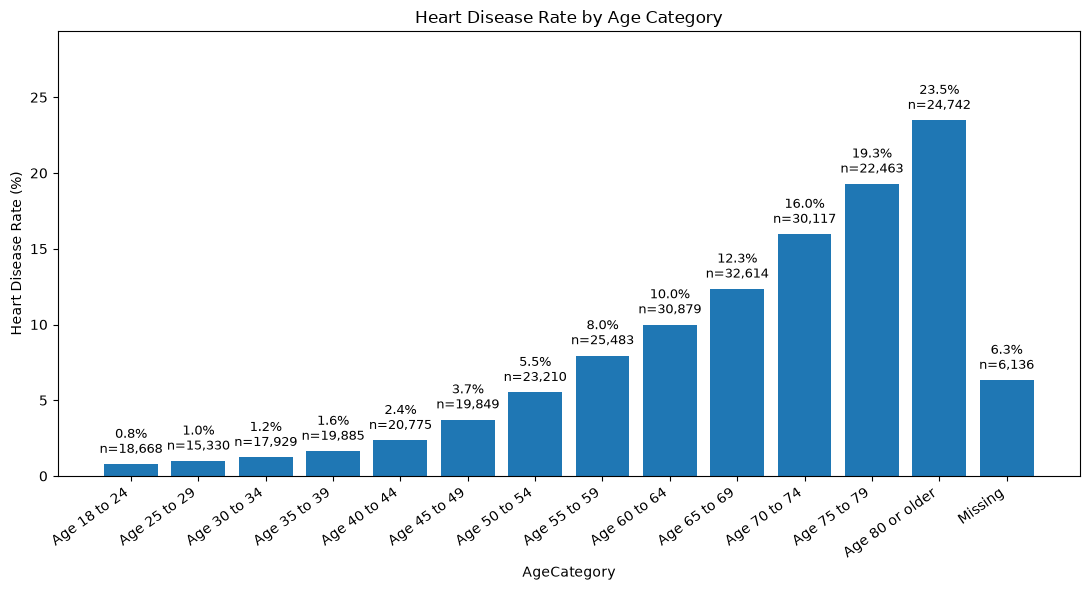


Saved: ..\results\figures\01_heart_disease_by_age.png
    AgeCategory  Total      Rate
   Age 18 to 24  18668  0.776730
   Age 25 to 29  15330  0.991520
   Age 30 to 34  17929  1.232640
   Age 35 to 39  19885  1.639427
   Age 40 to 44  20775  2.353791
   Age 45 to 49  19849  3.713033
   Age 50 to 54  23210  5.523481
   Age 55 to 59  25483  7.950398
   Age 60 to 64  30879  9.990609
   Age 65 to 69  32614 12.347458
   Age 70 to 74  30117 15.961085
   Age 75 to 79  22463 19.280595
Age 80 or older  24742 23.482338
        Missing   6136  6.323338


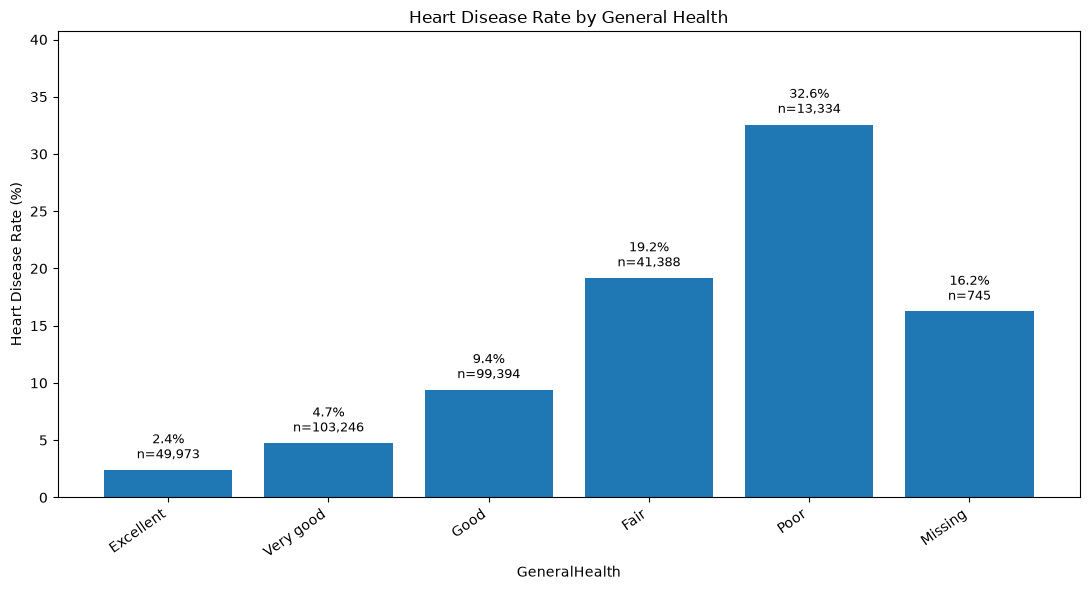


Saved: ..\results\figures\02_heart_disease_by_general_health.png
GeneralHealth  Total      Rate
    Excellent  49973  2.395293
    Very good 103246  4.737230
         Good  99394  9.398958
         Fair  41388 19.164975
         Poor  13334 32.570871
      Missing    745 16.241611


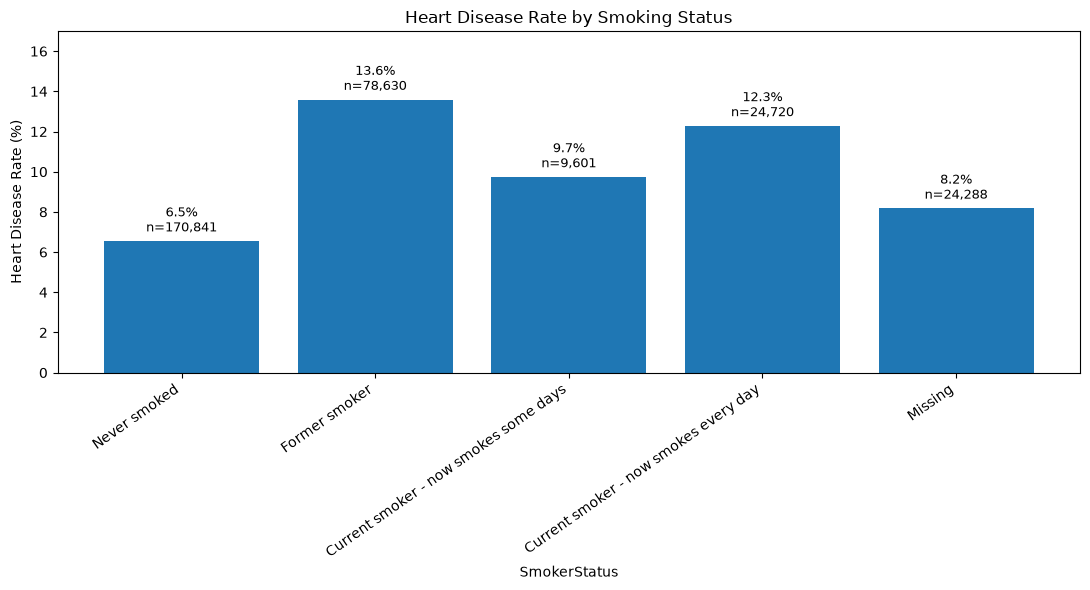


Saved: ..\results\figures\03_heart_disease_by_smoking.png
                         SmokerStatus  Total      Rate
                         Never smoked 170841  6.545853
                        Former smoker  78630 13.590233
Current smoker - now smokes some days   9601  9.738569
Current smoker - now smokes every day  24720 12.281553
                              Missing  24288  8.176877


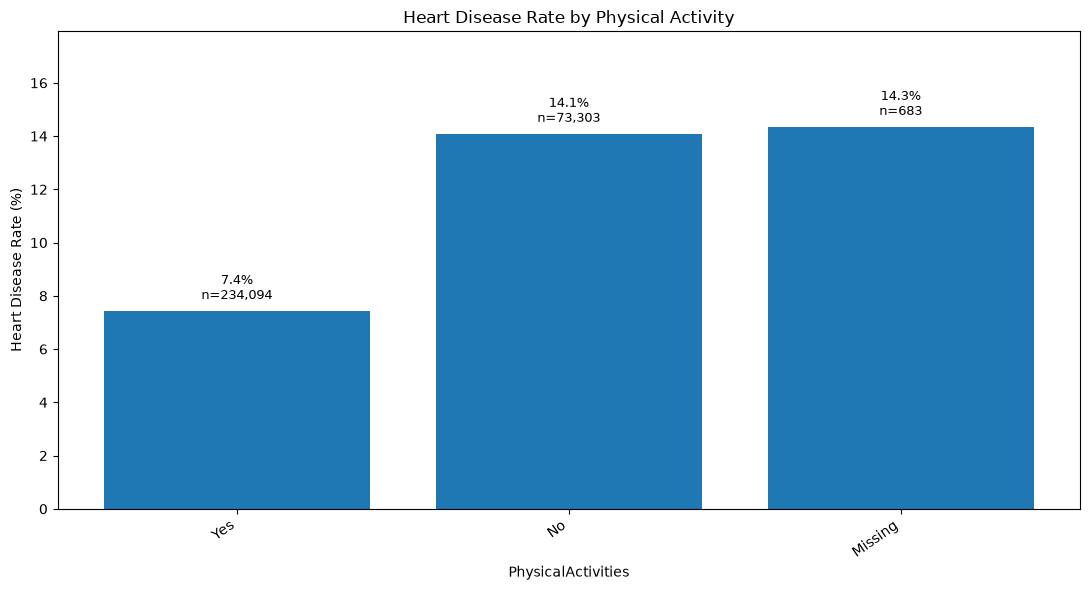


Saved: ..\results\figures\04_heart_disease_by_physical_activity.png
PhysicalActivities  Total      Rate
               Yes 234094  7.433339
                No  73303 14.088100
           Missing    683 14.348463


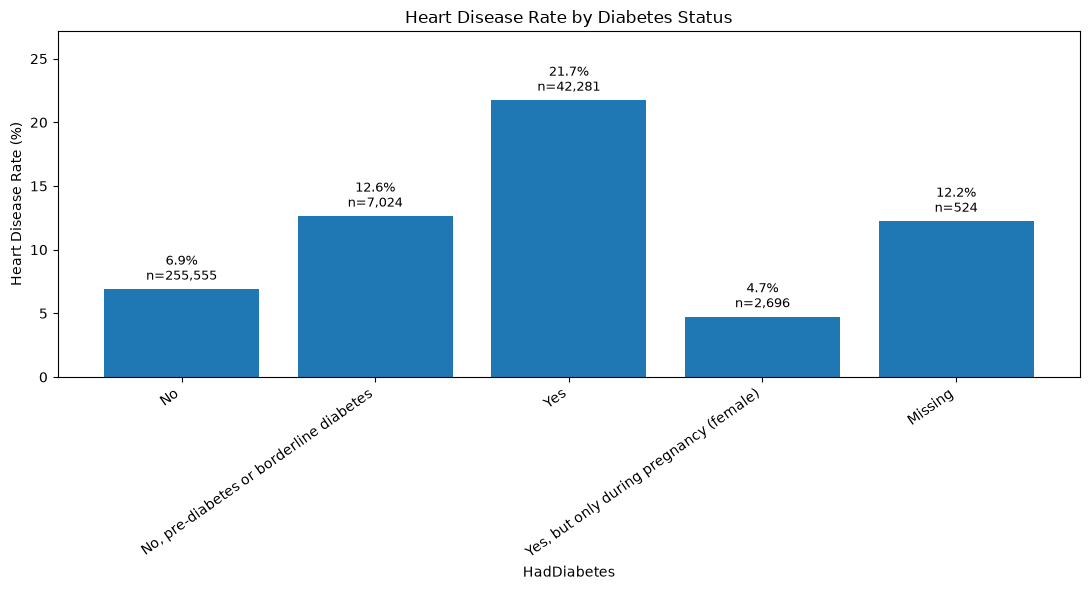


Saved: ..\results\figures\05_heart_disease_by_diabetes.png
                            HadDiabetes  Total      Rate
                                     No 255555  6.873667
No, pre-diabetes or borderline diabetes   7024 12.613895
                                    Yes  42281 21.718975
Yes, but only during pregnancy (female)   2696  4.710682
                                Missing    524 12.213740


In [127]:
save_rate_plot(
    "AgeCategory",
    "Heart Disease Rate by Age Category",
    "01_heart_disease_by_age.png",
    age_order
)

save_rate_plot(
    "GeneralHealth",
    "Heart Disease Rate by General Health",
    "02_heart_disease_by_general_health.png",
    ["Excellent", "Very good", "Good", "Fair", "Poor", "Missing"]
)

save_rate_plot(
    "SmokerStatus",
    "Heart Disease Rate by Smoking Status",
    "03_heart_disease_by_smoking.png",
    [
        "Never smoked",
        "Former smoker",
        "Current smoker - now smokes some days",
        "Current smoker - now smokes every day",
        "Missing"
    ]
)

save_rate_plot(
    "PhysicalActivities",
    "Heart Disease Rate by Physical Activity",
    "04_heart_disease_by_physical_activity.png",
    ["Yes", "No", "Missing"]
)

save_rate_plot(
    "HadDiabetes",
    "Heart Disease Rate by Diabetes Status",
    "05_heart_disease_by_diabetes.png",
    [
        "No",
        "No, pre-diabetes or borderline diabetes",
        "Yes",
        "Yes, but only during pregnancy (female)",
        "Missing"
    ]
)

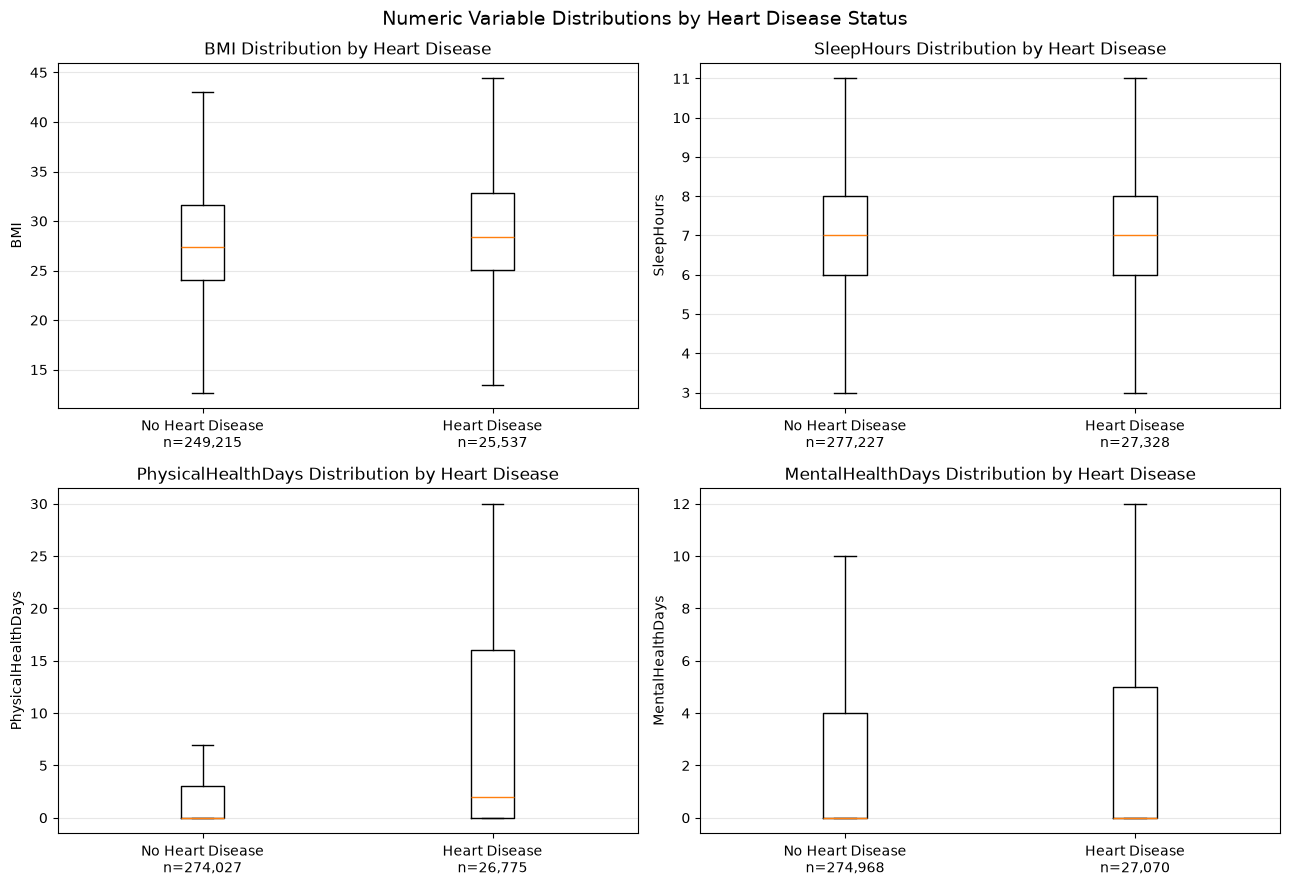

Saved: ..\results\figures\06_numeric_distributions_by_heart_disease.png


In [128]:
import matplotlib.pyplot as plt
import pandas as pd

numeric_features = [
    "BMI",
    "SleepHours",
    "PhysicalHealthDays",
    "MentalHealthDays"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, col in zip(axes, numeric_features):

    group_0 = pd.to_numeric(
        df.loc[df["heart_disease"] == 0, col],
        errors="coerce"
    ).dropna()

    group_1 = pd.to_numeric(
        df.loc[df["heart_disease"] == 1, col],
        errors="coerce"
    ).dropna()

    ax.boxplot(
        [group_0, group_1],
        tick_labels=[
            f"No Heart Disease\nn={len(group_0):,}",
            f"Heart Disease\nn={len(group_1):,}"
        ],
        showfliers=False
    )

    ax.set_title(f"{col} Distribution by Heart Disease")
    ax.set_ylabel(col)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Numeric Variable Distributions by Heart Disease Status",
    fontsize=14
)

plt.tight_layout()

save_path = figures_folder / "06_numeric_distributions_by_heart_disease.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved: {save_path}")

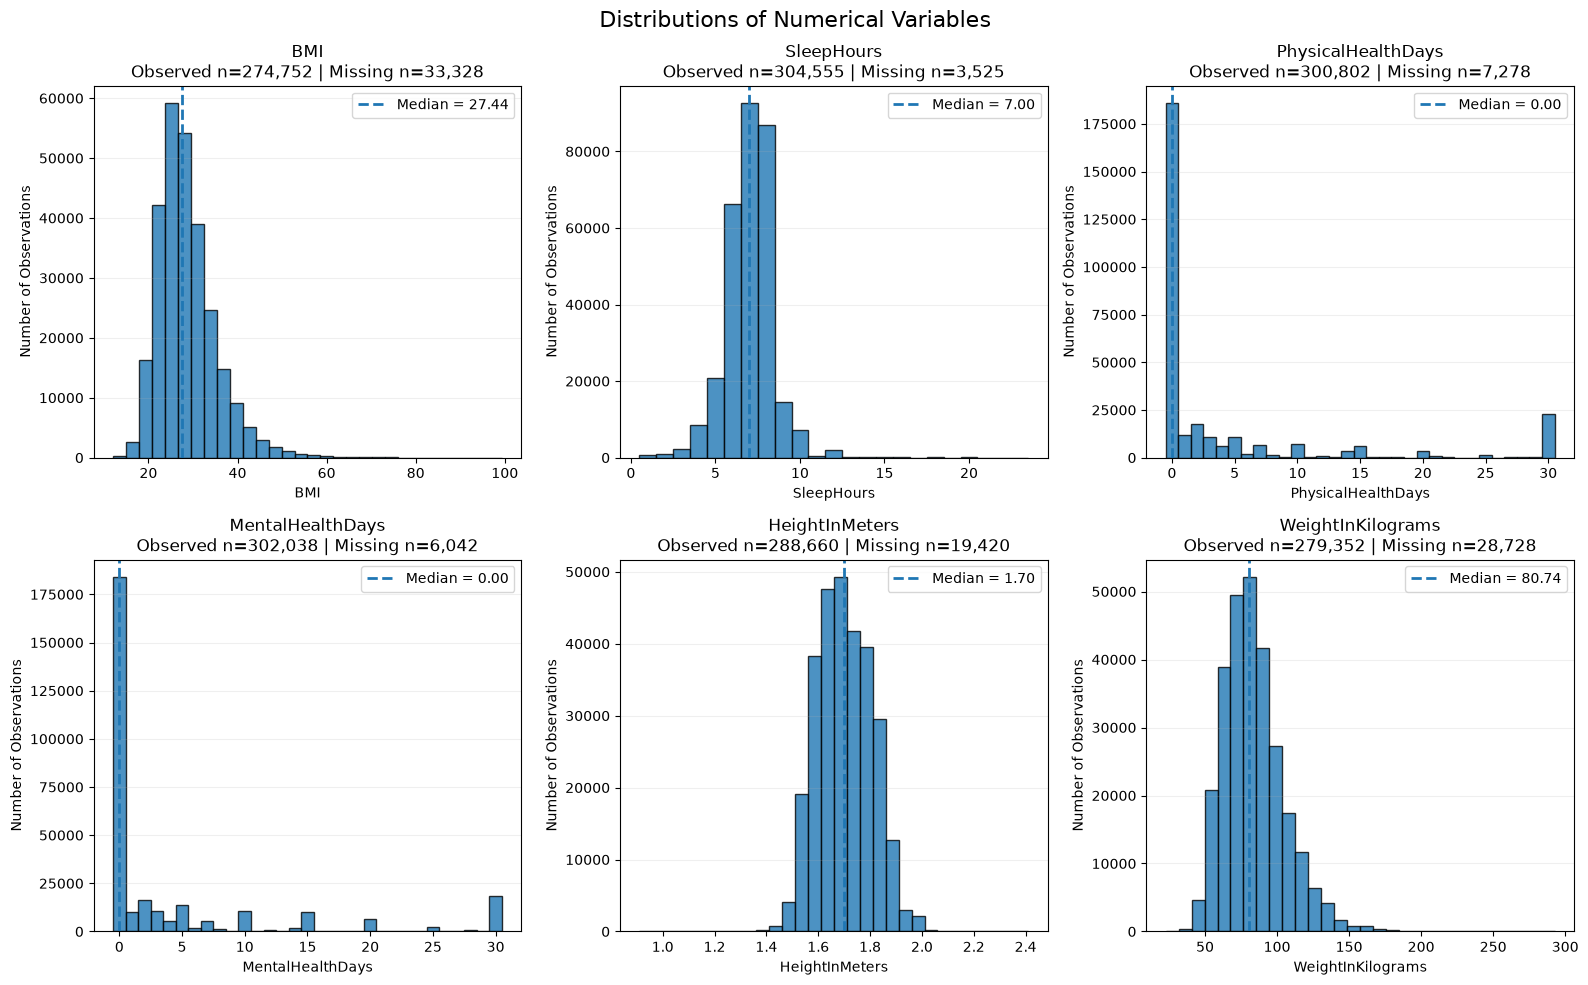


Saved: ..\results\figures\07_numerical_distributions.png

Numerical distribution summary:
                       count   mean    std    min    25%    50%    75%     max
BMI                 274752.0  28.53   6.55  12.06  24.13  27.44  31.75   99.34
SleepHours          304555.0   7.03   1.50   1.00   6.00   7.00   8.00   24.00
PhysicalHealthDays  300802.0   4.31   8.65   0.00   0.00   0.00   3.00   30.00
MentalHealthDays    302038.0   4.36   8.36   0.00   0.00   0.00   5.00   30.00
HeightInMeters      288660.0   1.70   0.11   0.91   1.63   1.70   1.78    2.41
WeightInKilograms   279352.0  83.10  21.46  22.68  68.04  80.74  95.25  292.57


In [129]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

numeric_features = [
    "BMI",
    "SleepHours",
    "PhysicalHealthDays",
    "MentalHealthDays",
    "HeightInMeters",
    "WeightInKilograms"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, col in zip(axes, numeric_features):

    values = pd.to_numeric(df[col], errors="coerce")
    observed = values.dropna()

    if col in ["PhysicalHealthDays", "MentalHealthDays"]:
        bins = np.arange(-0.5, 31.5, 1)
    elif col == "SleepHours":
        bins = np.arange(0.5, 24.5, 1)
    else:
        bins = 30

    ax.hist(
        observed,
        bins=bins,
        edgecolor="black",
        alpha=0.8
    )

    median_value = observed.median()

    ax.axvline(
        median_value,
        linestyle="--",
        linewidth=2,
        label=f"Median = {median_value:.2f}"
    )

    ax.set_title(
        f"{col}\nObserved n={len(observed):,} | Missing n={values.isna().sum():,}"
    )
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Observations")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "Distributions of Numerical Variables",
    fontsize=16
)

plt.tight_layout()

save_path = figures_folder / "07_numerical_distributions.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"\nSaved: {save_path}")
print("\nNumerical distribution summary:")

summary = df[numeric_features].describe().T
print(summary.round(2).to_string())

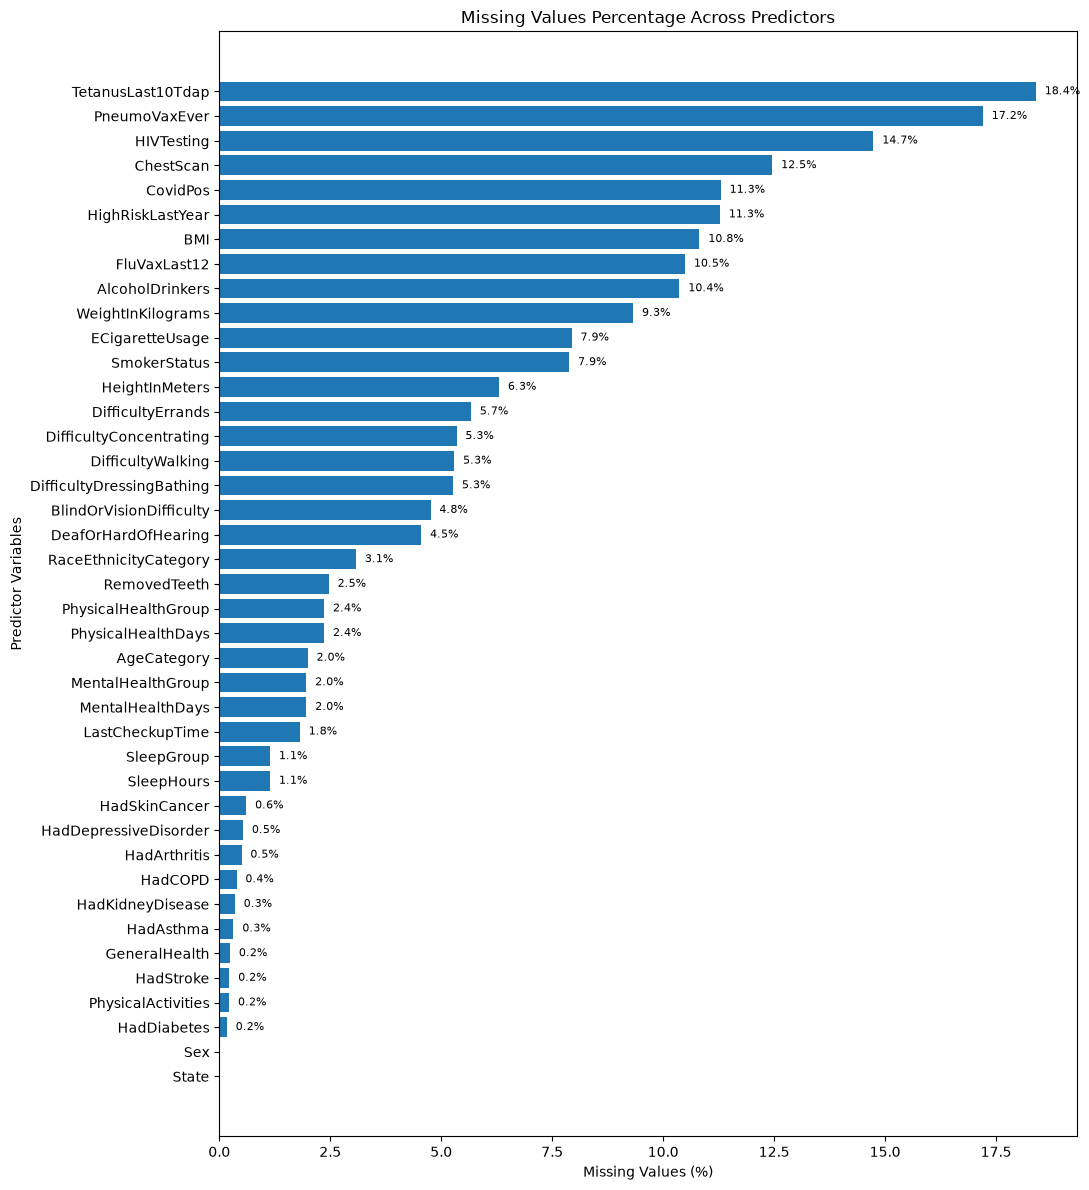

Saved: ..\results\figures\08_missingness_overview.png


In [130]:
import matplotlib.pyplot as plt

excluded_columns = [
    "row_id",
    "duplicate_group",
    "heart_disease",
    "HadHeartAttack",
    "HadAngina",
    "BMI_Group"
]

predictor_df = df.drop(
    columns=excluded_columns,
    errors="ignore"
)

missing_percent = (
    predictor_df.isnull().mean() * 100
).sort_values(ascending=True)

plt.figure(figsize=(11, 12))

bars = plt.barh(
    missing_percent.index,
    missing_percent.values
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Predictor Variables")
plt.title("Missing Values Percentage Across Predictors")

for bar, value in zip(bars, missing_percent.values):
    if value > 0:
        plt.text(
            value + 0.2,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center",
            fontsize=8
        )

plt.tight_layout()

save_path = figures_folder / "08_missingness_overview.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved: {save_path}")

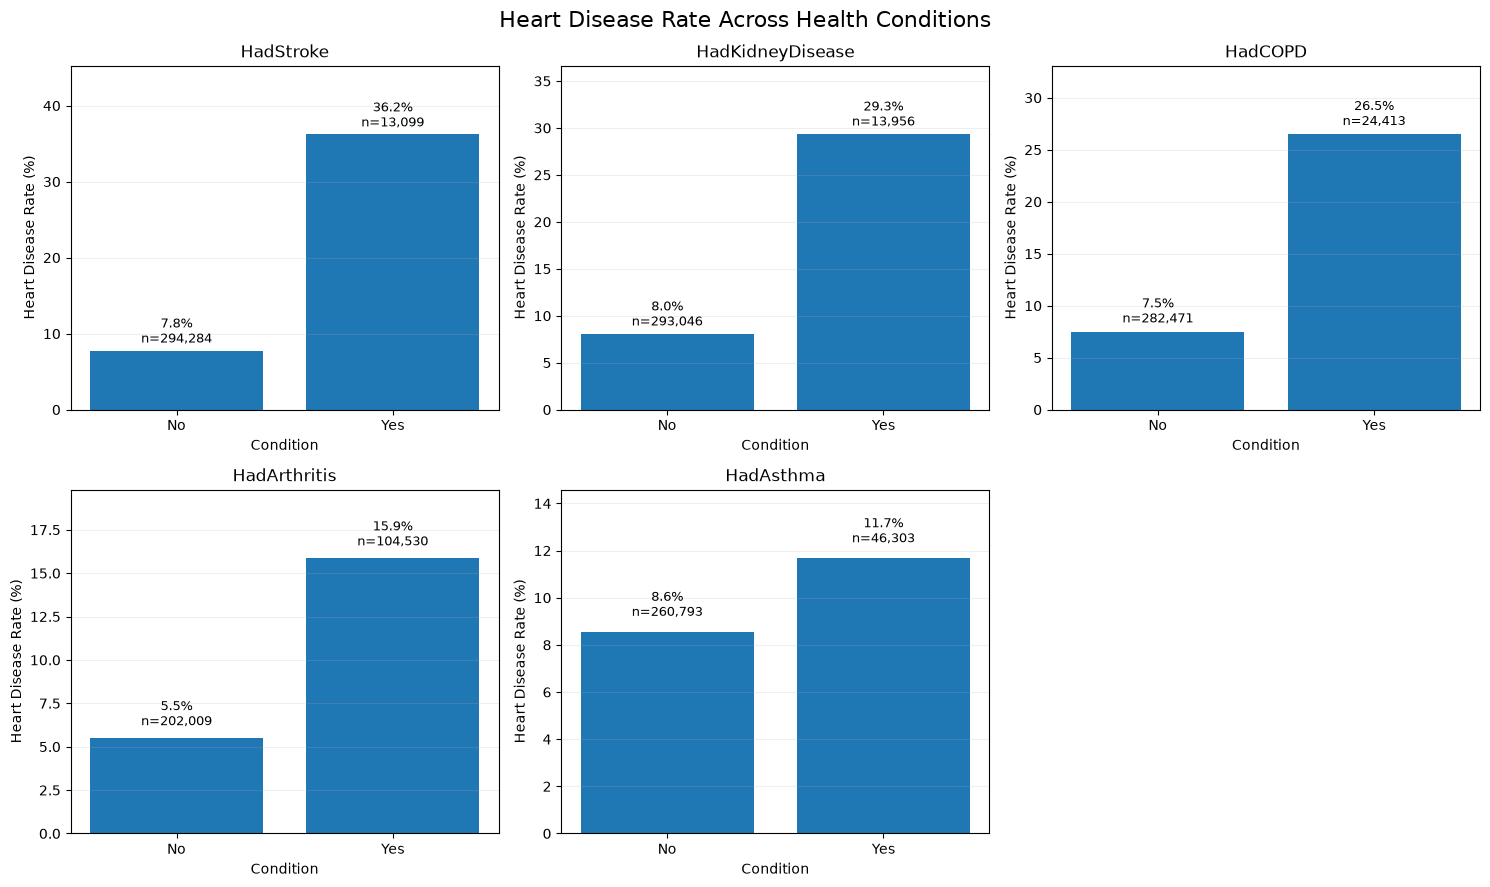

Saved: ..\results\figures\11_heart_disease_by_health_conditions.png

Heart Disease Rate Summary:
         Feature  Total  Heart_Disease_Cases  Heart_Disease_Rate
       HadStroke 294284                22879                7.77
       HadStroke  13099                 4743               36.21
HadKidneyDisease 293046                23488                8.02
HadKidneyDisease  13956                 4090               29.31
         HadCOPD 282471                21140                7.48
         HadCOPD  24413                 6462               26.47
    HadArthritis 202009                11104                5.50
    HadArthritis 104530                16576               15.86
       HadAsthma 260793                22301                8.55
       HadAsthma  46303                 5405               11.67

Missing Values:
HadStroke            697
HadKidneyDisease    1078
HadCOPD             1196
HadArthritis        1541
HadAsthma            984


In [131]:
import matplotlib.pyplot as plt
import pandas as pd

health_conditions = [
    "HadStroke",
    "HadKidneyDisease",
    "HadCOPD",
    "HadArthritis",
    "HadAsthma"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

summary_results = []

for ax, col in zip(axes, health_conditions):

    temp = df[[col, "heart_disease"]].dropna()

    summary = (
        temp.groupby(col)["heart_disease"]
        .agg(
            Total="count",
            Heart_Disease_Cases="sum",
            Heart_Disease_Rate="mean"
        )
        .reset_index()
    )

    summary["Heart_Disease_Rate"] *= 100

    summary_results.append(
        summary.assign(Feature=col)
    )

    summary = summary.set_index(col).reindex(["No", "Yes"])

    bars = ax.bar(
        ["No", "Yes"],
        summary["Heart_Disease_Rate"]
    )

    ax.set_title(col)
    ax.set_xlabel("Condition")
    ax.set_ylabel("Heart Disease Rate (%)")

    for bar, category in zip(bars, ["No", "Yes"]):
        rate = summary.loc[category, "Heart_Disease_Rate"]
        count = summary.loc[category, "Total"]

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{rate:.1f}%\nn={count:,.0f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_ylim(
        0,
        summary["Heart_Disease_Rate"].max() * 1.25
    )

    ax.grid(axis="y", alpha=0.2)

axes[-1].axis("off")

fig.suptitle(
    "Heart Disease Rate Across Health Conditions",
    fontsize=16
)

plt.tight_layout()

save_path = figures_folder / "11_heart_disease_by_health_conditions.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved: {save_path}")

print("\nHeart Disease Rate Summary:")
final_summary = pd.concat(summary_results, ignore_index=True)

print(
    final_summary[
        ["Feature", "Total", "Heart_Disease_Cases", "Heart_Disease_Rate"]
    ].round(2).to_string(index=False)
)

print("\nMissing Values:")
print(df[health_conditions].isna().sum().to_string())

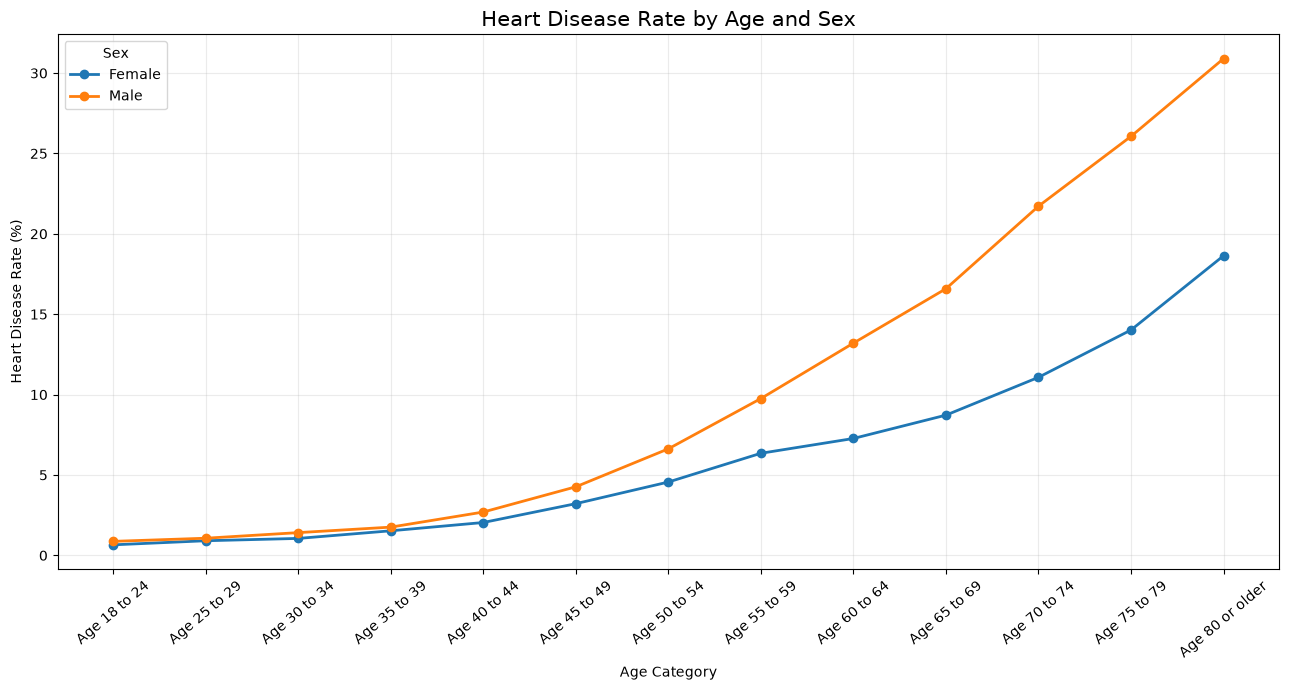

Saved: ..\results\figures\12_heart_disease_by_age_and_sex.png

Heart Disease Rate by Age and Sex:
Sex              Female   Male
AgeCategory                   
Age 18 to 24       0.65   0.87
Age 25 to 29       0.91   1.07
Age 30 to 34       1.05   1.41
Age 35 to 39       1.53   1.76
Age 40 to 44       2.04   2.69
Age 45 to 49       3.21   4.26
Age 50 to 54       4.56   6.63
Age 55 to 59       6.35   9.75
Age 60 to 64       7.27  13.20
Age 65 to 69       8.72  16.59
Age 70 to 74      11.07  21.72
Age 75 to 79      14.02  26.06
Age 80 or older   18.64  30.90

Sample Sizes:
Sex              Female   Male
AgeCategory                   
Age 18 to 24       8097  10571
Age 25 to 29       7262   8068
Age 30 to 34       9017   8912
Age 35 to 39      10146   9739
Age 40 to 44      10867   9908
Age 45 to 49      10420   9429
Age 50 to 54      12388  10822
Age 55 to 59      13497  11986
Age 60 to 64      16713  14166
Age 65 to 69      17577  15037
Age 70 to 74      16290  13827
Age 75 to 79      1

In [132]:
import matplotlib.pyplot as plt
import pandas as pd

# Calculate heart disease rate by age and sex
temp = df[
    ["AgeCategory", "Sex", "heart_disease"]
].dropna()

summary = (
    temp.groupby(["AgeCategory", "Sex"], observed=False)
    ["heart_disease"]
    .agg(
        Total="count",
        Heart_Disease_Rate="mean"
    )
    .reset_index()
)

summary["Heart_Disease_Rate"] *= 100

# Preserve age category order
age_order = [
    "Age 18 to 24",
    "Age 25 to 29",
    "Age 30 to 34",
    "Age 35 to 39",
    "Age 40 to 44",
    "Age 45 to 49",
    "Age 50 to 54",
    "Age 55 to 59",
    "Age 60 to 64",
    "Age 65 to 69",
    "Age 70 to 74",
    "Age 75 to 79",
    "Age 80 or older"
]

fig, ax = plt.subplots(figsize=(13, 7))

for sex in ["Female", "Male"]:

    sex_data = (
        summary[summary["Sex"] == sex]
        .set_index("AgeCategory")
        .reindex(age_order)
    )

    ax.plot(
        age_order,
        sex_data["Heart_Disease_Rate"],
        marker="o",
        linewidth=2,
        markersize=6,
        label=sex
    )

ax.set_title("Heart Disease Rate by Age and Sex", fontsize=15)
ax.set_xlabel("Age Category")
ax.set_ylabel("Heart Disease Rate (%)")

ax.tick_params(axis="x", rotation=40)
ax.legend(title="Sex")
ax.grid(alpha=0.25)

plt.tight_layout()

save_path = figures_folder / "12_heart_disease_by_age_and_sex.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved: {save_path}")

print("\nHeart Disease Rate by Age and Sex:")
print(
    summary.pivot(
        index="AgeCategory",
        columns="Sex",
        values="Heart_Disease_Rate"
    ).reindex(age_order).round(2).to_string()
)

print("\nSample Sizes:")
print(
    summary.pivot(
        index="AgeCategory",
        columns="Sex",
        values="Total"
    ).reindex(age_order).to_string()
)

## 11. Additional checks and summary-table exports

The next cells produce supplementary summaries for sleep duration, BMI missingness within age categories, height and weight by outcome, age-stratified vaccination comparisons, categorical summaries that include a `Missing` category, and CSV exports for the Member 2 handoff.

In [133]:
# Test whether the overall BMI-missingness difference persists within age categories.
tmp = df.assign(BMI_missing=df["BMI"].isna())
bmi_missing_by_age = (
    tmp.groupby(["AgeCategory", "BMI_missing"], observed=True)["heart_disease"]
       .agg(Total="count", Heart_Disease_Rate="mean")
       .reset_index()
)
bmi_missing_by_age["Heart_Disease_Rate"] *= 100
print("BMI missingness and heart disease rate within age categories:")
print(bmi_missing_by_age.round(2).to_string(index=False))
print("\nPivoted rates (%):")
bmi_missing_age_pivot = bmi_missing_by_age.pivot(
    index="AgeCategory", columns="BMI_missing", values="Heart_Disease_Rate"
).rename(columns={False: "BMI available", True: "BMI missing"})
print(bmi_missing_age_pivot.round(2).to_string())

BMI missingness and heart disease rate within age categories:
    AgeCategory  BMI_missing  Total  Heart_Disease_Rate
   Age 18 to 24        False  16535                0.70
   Age 18 to 24         True   2133                1.41
   Age 25 to 29        False  13459                0.96
   Age 25 to 29         True   1871                1.23
   Age 30 to 34        False  15594                1.21
   Age 30 to 34         True   2335                1.37
   Age 35 to 39        False  17538                1.65
   Age 35 to 39         True   2347                1.53
   Age 40 to 44        False  18465                2.34
   Age 40 to 44         True   2310                2.42
   Age 45 to 49        False  17708                3.78
   Age 45 to 49         True   2141                3.18
   Age 50 to 54        False  20764                5.62
   Age 50 to 54         True   2446                4.74
   Age 55 to 59        False  22916                7.99
   Age 55 to 59         True   2567       

In [134]:
# Check vaccination percentages within age categories (descriptive age-stratified comparison).
vaccination_features = ["FluVaxLast12", "PneumoVaxEver", "TetanusLast10Tdap"]
vaccination_by_age_rows = []
for feature in vaccination_features:
    temp = df[["AgeCategory", feature, "heart_disease"]].copy()
    temp[feature] = temp[feature].astype("object").fillna("Missing")
    summary = (
        temp.groupby(["AgeCategory", feature], dropna=False, observed=True)["heart_disease"]
            .agg(Total="count", Heart_Disease_Rate="mean")
            .reset_index()
    )
    summary["Heart_Disease_Rate"] *= 100
    summary.insert(0, "Feature", feature)
    vaccination_by_age_rows.append(summary)
vaccination_by_age = pd.concat(vaccination_by_age_rows, ignore_index=True)
print("Vaccination comparisons stratified by age:")
print(vaccination_by_age.round(2).to_string(index=False))

Vaccination comparisons stratified by age:
          Feature     AgeCategory FluVaxLast12  Total  Heart_Disease_Rate PneumoVaxEver                                         TetanusLast10Tdap
     FluVaxLast12    Age 18 to 24      Missing   2046                0.93           NaN                                                       NaN
     FluVaxLast12    Age 18 to 24           No  11233                0.81           NaN                                                       NaN
     FluVaxLast12    Age 18 to 24          Yes   5389                0.65           NaN                                                       NaN
     FluVaxLast12    Age 25 to 29      Missing   1575                1.59           NaN                                                       NaN
     FluVaxLast12    Age 25 to 29           No   9094                0.90           NaN                                                       NaN
     FluVaxLast12    Age 25 to 29          Yes   4661                0.97        

In [135]:
# Consistent categorical heart-disease summary: every feature includes an explicit Missing category.
excluded_for_summary = {
    "row_id", "duplicate_group", "heart_disease", "HadHeartAttack", "HadAngina"
}
categorical_summary_rows = []
for feature in df.select_dtypes(include=["object", "category"]).columns:
    if feature in excluded_for_summary:
        continue
    temp = df[[feature, "heart_disease"]].copy()
    temp[feature] = temp[feature].astype("object").fillna("Missing")
    summary = (
        temp.groupby(feature, dropna=False)["heart_disease"]
            .agg(Total="count", Heart_Disease_Cases="sum", Heart_Disease_Rate="mean")
            .reset_index()
            .rename(columns={feature: "Category"})
    )
    summary["Heart_Disease_Rate"] *= 100
    summary.insert(0, "Feature", feature)
    categorical_summary_rows.append(summary)
categorical_rate_summary = pd.concat(categorical_summary_rows, ignore_index=True)
print("Categorical summaries created, including Missing categories:", categorical_rate_summary.shape)
print(categorical_rate_summary.head(20).round(2).to_string(index=False))

C:\Users\yara\AppData\Local\Temp\ipykernel_4436\3996841567.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for feature in df.select_dtypes(include=["object", "category"]).columns:


Categorical summaries created, including Missing categories: (195, 5)
Feature             Category  Total  Heart_Disease_Cases  Heart_Disease_Rate
  State              Alabama   3125                  402               12.86
  State               Alaska   4007                  334                8.34
  State              Arizona   6936                  706               10.18
  State             Arkansas   3621                  507               14.00
  State           California   7634                  488                6.39
  State             Colorado   6482                  362                5.58
  State          Connecticut   6741                  501                7.43
  State             Delaware   2760                  243                8.80
  State District of Columbia   2224                  133                5.98
  State              Florida   9313                 1137               12.21
  State              Georgia   6391                  632                9.89
  Stat

In [136]:
# Export key summary tables required for the Member 2 handoff.
from pathlib import Path

tables_folder = Path("../results/tables")
tables_folder.mkdir(parents=True, exist_ok=True)

missingness_table = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": df.isna().mean() * 100
}).query("Missing_Count > 0").sort_values("Missing_Percent", ascending=False)

age_summary_export = (
    df.groupby("AgeCategory", observed=True)["heart_disease"]
      .agg(Total="count", Heart_Disease_Cases="sum", Heart_Disease_Rate="mean")
      .reset_index()
)
age_summary_export["Heart_Disease_Rate"] *= 100

numeric_by_outcome_export = df.groupby("heart_disease")[[
    "BMI", "SleepHours", "PhysicalHealthDays", "MentalHealthDays",
    "HeightInMeters", "WeightInKilograms"
]].agg(["count", "mean", "median", "std"])

spearman_export = df[[
    "BMI", "SleepHours", "PhysicalHealthDays", "MentalHealthDays",
    "HeightInMeters", "WeightInKilograms"
]].corr(method="spearman")

exports = {
    "missingness_summary.csv": missingness_table,
    "heart_disease_by_age.csv": age_summary_export,
    "categorical_heart_disease_rates.csv": categorical_rate_summary,
    "sleep_group_summary.csv": sleep_group_summary.reset_index(),
    "bmi_missingness_by_age.csv": bmi_missing_by_age,
    "height_weight_by_outcome.csv": height_weight_by_outcome,
    "vaccination_by_age.csv": vaccination_by_age,
    "numeric_summary_by_outcome.csv": numeric_by_outcome_export,
    "spearman_correlation.csv": spearman_export
}

for filename, table in exports.items():
    table.to_csv(tables_folder / filename, index=True if isinstance(table.columns, pd.MultiIndex) else False)
    print(f"Saved: {tables_folder / filename}")

Saved: ..\results\tables\missingness_summary.csv
Saved: ..\results\tables\heart_disease_by_age.csv
Saved: ..\results\tables\categorical_heart_disease_rates.csv
Saved: ..\results\tables\sleep_group_summary.csv
Saved: ..\results\tables\bmi_missingness_by_age.csv
Saved: ..\results\tables\height_weight_by_outcome.csv
Saved: ..\results\tables\vaccination_by_age.csv
Saved: ..\results\tables\numeric_summary_by_outcome.csv
Saved: ..\results\tables\spearman_correlation.csv


In [137]:
saved_figures = sorted(figures_folder.glob("*.png"))

print(f"Total saved figures: {len(saved_figures)}")
print("\nSaved Figure Files:")

for file in saved_figures:
    print(file.name)

Total saved figures: 13

Saved Figure Files:
01_heart_disease_by_age.png
02_heart_disease_by_general_health.png
03_heart_disease_by_smoking.png
04_heart_disease_by_physical_activity.png
05_heart_disease_by_diabetes.png
06_numeric_distributions_by_heart_disease.png
07_numerical_distributions.png
08_missingness_overview.png
09_spearman_correlation_heatmap.png
10_grouped_numeric_rates.png
11_heart_disease_by_health_conditions.png
12_heart_disease_by_age_and_sex.png
13_within_age_smoking_activity.png


## 12. Key findings

- The target is imbalanced, with approximately **9.03%** positive cases.
- Age and self-reported general health show clear descriptive gradients with heart disease.
- Diabetes, smoking status, physical activity, BMI, physical health days and several co-existing conditions also show differences across categories.
- Sleep duration appears non-linear, with the 6–8 hour group showing the lowest observed percentage.
- Missingness varies by feature and may differ across demographic groups; its mechanism is not established.
- Overall vaccination comparisons are likely influenced by age and health composition and should not be interpreted causally.
- BMI and weight are strongly correlated, so their joint use should be assessed rather than assumed.

These are exploratory observations, not a final ranking of predictive features.

## 13. Limitations


- This notebook uses the observed training split only. Findings should not be generalized to unseen data without validation.
- Missing-data mechanisms are not established by these analyses.
- Age and sex composition can influence overall comparisons; stratification helps assess this but does not remove all confounding.
- Rare categories and small subgroups may produce unstable percentages.
- EDA is descriptive and does not establish causal relationships or final predictive importance.

## 14. Preparation recommendations and handoff to Member 3

| Area | Recommendation |
|---|---|
| Target and leakage | Keep `heart_disease` as the target. Exclude target-source fields such as `HadHeartAttack` and `HadAngina` from predictors, and exclude metadata identifiers such as `row_id` and `duplicate_group`. |
| Missing values | Report missingness by feature. Fit imputation steps using training data only and within the modelling pipeline to avoid leakage. |
| BMI and body measurements | Treat BMI as a candidate feature, but assess redundancy with weight and height. Do not automatically include all three without validation. |
| Outliers | Treat flagged values as review candidates, not automatic deletions. Check plausibility and assess sensitivity of model results. |
| Categorical features | Preserve meaningful categories and handle missing categories consistently between training and inference. Review rare categories and inconsistent labels. |
| Age and health conditions | Consider age and co-existing conditions as important context; interpret crude associations cautiously because of confounding. |
| Model evaluation | Because the positive class is relatively uncommon, report recall, precision, F1, PR-AUC and the confusion matrix in addition to accuracy. |
| Feature selection | Use model-based importance and validation results to decide the final feature set. EDA percentages alone are not feature-importance rankings. |

